# UTS Machine Learning — Klasifikasi Niat Pembelian Pengunjung Situs E-Commerce

**Jalur:** A (Klasifikasi)
**Dataset:** Online Shoppers Purchasing Intention
**NIM:** 2301010379 · **Nama:** Rafi Akmal Widikta · **Kelas:** Informatika XX

> **`SEED = 379`** adalah tiga digit terakhir NIM **2301010379** dan sudah dipakai di seluruh proses:
> pembagian data, 5-fold cross-validation, dan model SVM. Notebook ini sudah dijalankan penuh
> (**Run All**) sehingga semua keluaran dan angka pada narasi sudah konsisten dengan `SEED` tersebut.

## 0. Menetapkan SEED

Seluruh proses yang mengandung keacakan — pembagian data, cross-validation, dan SVM — memakai satu
nilai `SEED` yang sama agar hasil dapat direproduksi.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, auc,
                             classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold,
                                    cross_val_score, train_test_split)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.utils.validation import check_array

warnings.filterwarnings("ignore")
pd.set_option("display.width", 130)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

# ============================================================
# SEED = tiga digit terakhir NIM.  Contoh: NIM 2301010123 -> 123
# ============================================================
SEED = 379

print("SEED =", SEED)

SEED = 379


## 1. Pemahaman Masalah dan Data

### 1.1 Tujuan analisis

Sebuah situs e-commerce ingin mengetahui **apakah sebuah sesi kunjungan akan berakhir dengan transaksi
(`Revenue = True`)**. Catatan historis 12.330 sesi tersedia, tetapi belum dimanfaatkan untuk mengambil
keputusan.

Tujuan analisis ini adalah membangun model klasifikasi yang memprediksi niat pembelian berdasarkan
**perilaku navigasi selama sesi berlangsung** — jumlah halaman yang dibuka, durasi, tingkat bounce,
nilai halaman, dan atribut kunjungan lainnya.

### 1.2 Pengguna hasil dan keputusan yang terbantu

| Pengguna | Keputusan yang terbantu |
| --- | --- |
| Tim pemasaran digital | Menentukan sesi mana yang layak diberi **voucher diskon** secara *real-time*, agar anggaran promosi tidak habis untuk pengunjung yang memang tidak akan membeli. |
| Tim produk / UX | Mengenali pola navigasi yang berujung pembelian, lalu mereplikasinya pada halaman dengan tingkat *bounce* tinggi. |
| Tim retargeting | Memprioritaskan pengunjung berprobabilitas tinggi untuk diingatkan kembali lewat iklan atau surel. |

Nilai ekonominya konkret: setiap sesi yang berhasil diarahkan ke pembelian menambah pendapatan,
sedangkan setiap voucher yang salah sasaran adalah biaya yang hangus.

### 1.3 Sumber data

| Keterangan | Isi |
| --- | --- |
| Judul dataset | Online Shoppers Purchasing Intention Dataset |
| Sumber (Kaggle) | https://www.kaggle.com/datasets/satyajeetkumarraj/online-shoppers-purchasing-intention-dataset |
| Sumber asli (otoritatif) | UCI ML Repository, dataset ID 468 — https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset |
| DOI dataset | 10.24432/C5F88Q |
| Tanggal akses | 24 November 2026 |
| Lisensi | **CC BY 4.0** (Creative Commons Attribution 4.0 International) |
| Ukuran | 12.330 baris × 18 kolom (17 fitur + 1 target) |
| Rujukan | Sakar, C.O., Polat, S.O., Katircioglu, M., & Kastro, Y. (2019). *Real-time prediction of online shoppers' purchasing intention using multilayer perceptron and LSTM recurrent neural networks.* Neural Computing and Applications, 31(10), 6893–6908. |

**Kepatuhan UU No. 27 Tahun 2022 (Pelindungan Data Pribadi).** Dataset ini **tidak memuat identitas
perseorangan**: tidak ada nama, NIK, alamat, nomor telepon, maupun surel. Setiap baris adalah satu sesi
anonim dari pengguna berbeda dalam rentang satu tahun. Kolom `OperatingSystems`, `Browser`, `Region`,
dan `TrafficType` sudah dikodekan sebagai **angka tanpa pemetaan** ke merek, perangkat, atau wilayah
sebenarnya, sehingga tidak dapat dilacak ke individu mana pun. Karena itu tidak diperlukan proses
anonimisasi tambahan.

**Catatan verifikasi lisensi.** Lisensi **CC BY 4.0** dipastikan langsung pada halaman resmi UCI (sumber
asli dataset), yang menyatakan: *"This dataset is licensed under a Creative Commons Attribution 4.0
International (CC BY 4.0) license."* Tautan Kaggle yang dipakai juga mencantumkan *"Attribution 4.0
International (CC BY 4.0)"* secara eksplisit, dan berkasnya **identik** dengan versi UCI (diverifikasi
dengan pencocokan hash). Sebagian unggahan ulang dataset ini di Kaggle hanya memberi label lisensi
"Other (specified in description)", sehingga sengaja tidak dipakai sebagai rujukan utama.

### 1.4 Deskripsi kolom

Tabel disusun dari dokumentasi UCI. Kolom **Satuan/rentang** penting agar pembaca menyadari bahwa
sebagian fitur adalah **hitungan halaman**, sebagian **durasi detik**, dan sebagian **proporsi 0–1** —
ketiganya tidak boleh diperlakukan sama saat scaling.

In [2]:
deskripsi = pd.DataFrame([
    ["Administrative", "int", "Jumlah halaman akun/administratif yang dibuka", "halaman (0-27)"],
    ["Administrative_Duration", "float", "Total waktu di halaman administratif", "detik (0-3398)"],
    ["Informational", "int", "Jumlah halaman informasi (tentang kami, kebijakan, dll.)", "halaman (0-24)"],
    ["Informational_Duration", "float", "Total waktu di halaman informasi", "detik (0-2549)"],
    ["ProductRelated", "int", "Jumlah halaman produk yang dibuka", "halaman (0-705)"],
    ["ProductRelated_Duration", "float", "Total waktu di halaman produk", "detik (0-63.973)"],
    ["BounceRates", "float", "Rata-rata rasio pengunjung yang masuk lalu langsung keluar", "proporsi (0-0,2)"],
    ["ExitRates", "float", "Rata-rata rasio halaman tempat pengunjung keluar", "proporsi (0-0,2)"],
    ["PageValues", "float", "Rata-rata nilai halaman yang dikunjungi sebelum transaksi", "skor (0-361)"],
    ["SpecialDay", "float", "Kedekatan waktu kunjungan dengan hari besar", "indeks (0-1)"],
    ["Month", "kategori", "Bulan kunjungan", "Jan-Des"],
    ["OperatingSystems", "int (kode)", "Kode sistem operasi pengunjung", "kode 1-8"],
    ["Browser", "int (kode)", "Kode peramban yang dipakai", "kode 1-13"],
    ["Region", "int (kode)", "Kode wilayah geografis pengunjung", "kode 1-9"],
    ["TrafficType", "int (kode)", "Kode sumber lalu lintas (iklan, pencarian, langsung)", "kode 1-20"],
    ["VisitorType", "kategori", "Status pengunjung: baru atau berulang", "New/Returning/Other"],
    ["Weekend", "boolean", "Apakah kunjungan terjadi pada akhir pekan", "True/False"],
    ["Revenue", "boolean", "TARGET: apakah sesi berakhir dengan transaksi", "True/False"],
], columns=["Kolom", "Tipe", "Arti", "Satuan/rentang"])
deskripsi

,Kolom,Tipe,Arti,Satuan/rentang
0,Administrative,int,Jumlah halaman akun/administratif yang dibuka,halaman (0-27)
1,Administrative_Duration,float,Total waktu di halaman administratif,detik (0-3398)
2,Informational,int,"Jumlah halaman informasi (tentang kami, kebija...",halaman (0-24)
3,Informational_Duration,float,Total waktu di halaman informasi,detik (0-2549)
4,ProductRelated,int,Jumlah halaman produk yang dibuka,halaman (0-705)
5,ProductRelated_Duration,float,Total waktu di halaman produk,detik (0-63.973)
6,BounceRates,float,Rata-rata rasio pengunjung yang masuk lalu lan...,"proporsi (0-0,2)"
7,ExitRates,float,Rata-rata rasio halaman tempat pengunjung keluar,"proporsi (0-0,2)"
8,PageValues,float,Rata-rata nilai halaman yang dikunjungi sebelu...,skor (0-361)
9,SpecialDay,float,Kedekatan waktu kunjungan dengan hari besar,indeks (0-1)


In [3]:
df_raw = pd.read_csv("../data/online_shoppers_intention.csv")

print(f"Bentuk data mentah  : {df_raw.shape[0]:,} baris x {df_raw.shape[1]} kolom".replace(",", "."))
print(f"Jumlah nilai hilang : {df_raw.isna().sum().sum()}")
print(f"Baris duplikat      : {df_raw.duplicated().sum()}")
print("\nDistribusi target Revenue:")
print(df_raw["Revenue"].value_counts().to_string())
print("\nTipe data:")
print(df_raw.dtypes.to_string())

Bentuk data mentah  : 12.330 baris x 18 kolom
Jumlah nilai hilang : 0
Baris duplikat      : 125

Distribusi target Revenue:
Revenue
False    10422
True      1908

Tipe data:
Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                          str
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                    str
Weekend                       bool
Revenue                       bool


**Keputusan saya — Tahap 1**

Saya memilih **Jalur A (klasifikasi)** karena `Revenue` adalah target kategorikal biner dan tujuan
analisisnya memprediksi kejadian yang belum terjadi. Klasifikasi menghasilkan **probabilitas**, dan
probabilitas itulah yang dapat langsung dipakai tim pemasaran untuk memutuskan pemberian voucher —
bukan sekadar label ya/tidak.

Dataset ini memenuhi syarat minimum soal (12.330 baris > 200; 17 fitur > 4) dan bukan termasuk daftar
dataset yang dilarang. Lisensinya **CC BY 4.0**, sehingga kewajiban atribusi terpenuhi dan dataset boleh
disertakan di dalam repositori.

Keputusan penting: **kolom kode** (`OperatingSystems`, `Browser`, `Region`, `TrafficType`) saya
perlakukan sebagai **kategorikal, bukan numerik**. Alasannya, angka 1 dan 13 pada `Browser` bukan
besaran yang bisa dibandingkan — peramban nomor 13 tidak "tiga belas kali lebih besar" dari peramban
nomor 1. Memasukkannya sebagai angka menciptakan urutan palsu dan merusak perhitungan jarak pada KNN
maupun SVM. Konsekuensinya saya catat sebagai keterbatasan: tanpa kamus pemetaan, model tidak dapat
menyebutkan nama peramban atau wilayah secara spesifik.

## 2. Eksplorasi dan Visualisasi Data

Tiga grafik wajib Jalur A adalah **distribusi target**, **distribusi fitur**, dan **hubungan fitur
dengan target**. Saya menambahkan dua grafik pendukung — korelasi antar fitur dan boxplot outlier —
karena keduanya langsung menentukan keputusan pra-pemrosesan pada Tahap 3.

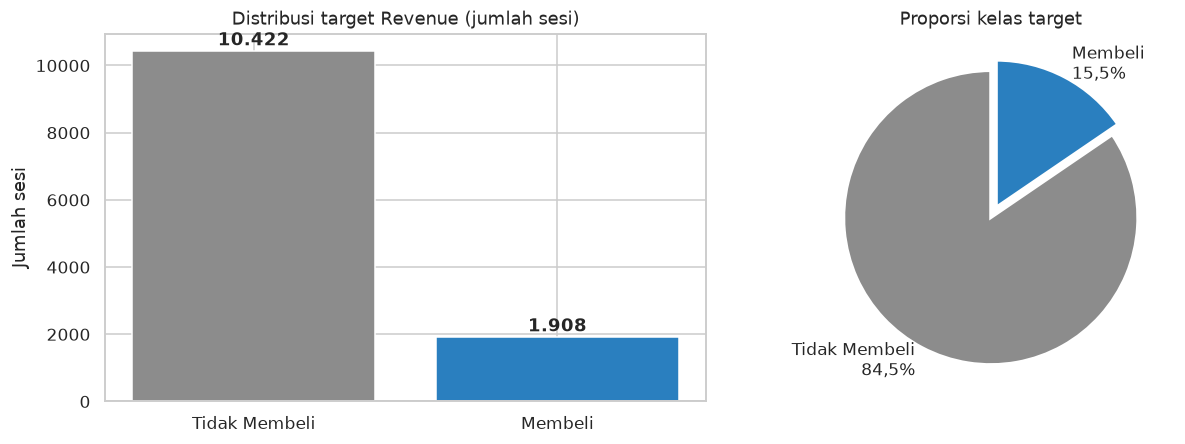

Nisbah ketidakseimbangan: 5.46 : 1


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

label = ["Tidak Membeli", "Membeli"]
jumlah = df_raw["Revenue"].value_counts().reindex([False, True])

axes[0].bar(label, jumlah.values, color=["#8c8c8c", "#2a7fbf"])
for i, v in enumerate(jumlah.values):
    axes[0].text(i, v + 180, f"{v:,}".replace(",", "."), ha="center", fontweight="bold")
axes[0].set_title("Distribusi target Revenue (jumlah sesi)")
axes[0].set_ylabel("Jumlah sesi")

persen = df_raw["Revenue"].value_counts(normalize=True).reindex([False, True]) * 100
axes[1].pie(persen.values, labels=[f"{l}\n{p:.1f}%".replace(".", ",") for l, p in zip(label, persen.values)],
            colors=["#8c8c8c", "#2a7fbf"], explode=(0, 0.08), startangle=90,
            wedgeprops={"edgecolor": "white", "linewidth": 2})
axes[1].set_title("Proporsi kelas target")

plt.tight_layout()
plt.savefig("../reports/fig01_distribusi_target.png", bbox_inches="tight")
plt.show()

print(f"Nisbah ketidakseimbangan: {jumlah.values[0] / jumlah.values[1]:.2f} : 1")

**Interpretasi Grafik 1.** Kelas sangat tidak seimbang: hanya **15,5%** sesi berakhir dengan pembelian
(1.908 dari 12.330), sedangkan 84,5% tidak. Nisbahnya **5,46 : 1**.

Implikasi langsungnya: **akurasi tidak bisa dipakai sebagai ukuran utama**. Model yang selalu menebak
"Tidak Membeli" akan memperoleh akurasi 84,5% tanpa mempelajari apa pun. Karena itu evaluasi pada
Tahap 5 harus bertumpu pada **presisi, recall, dan F1** untuk kelas minoritas (pembeli).

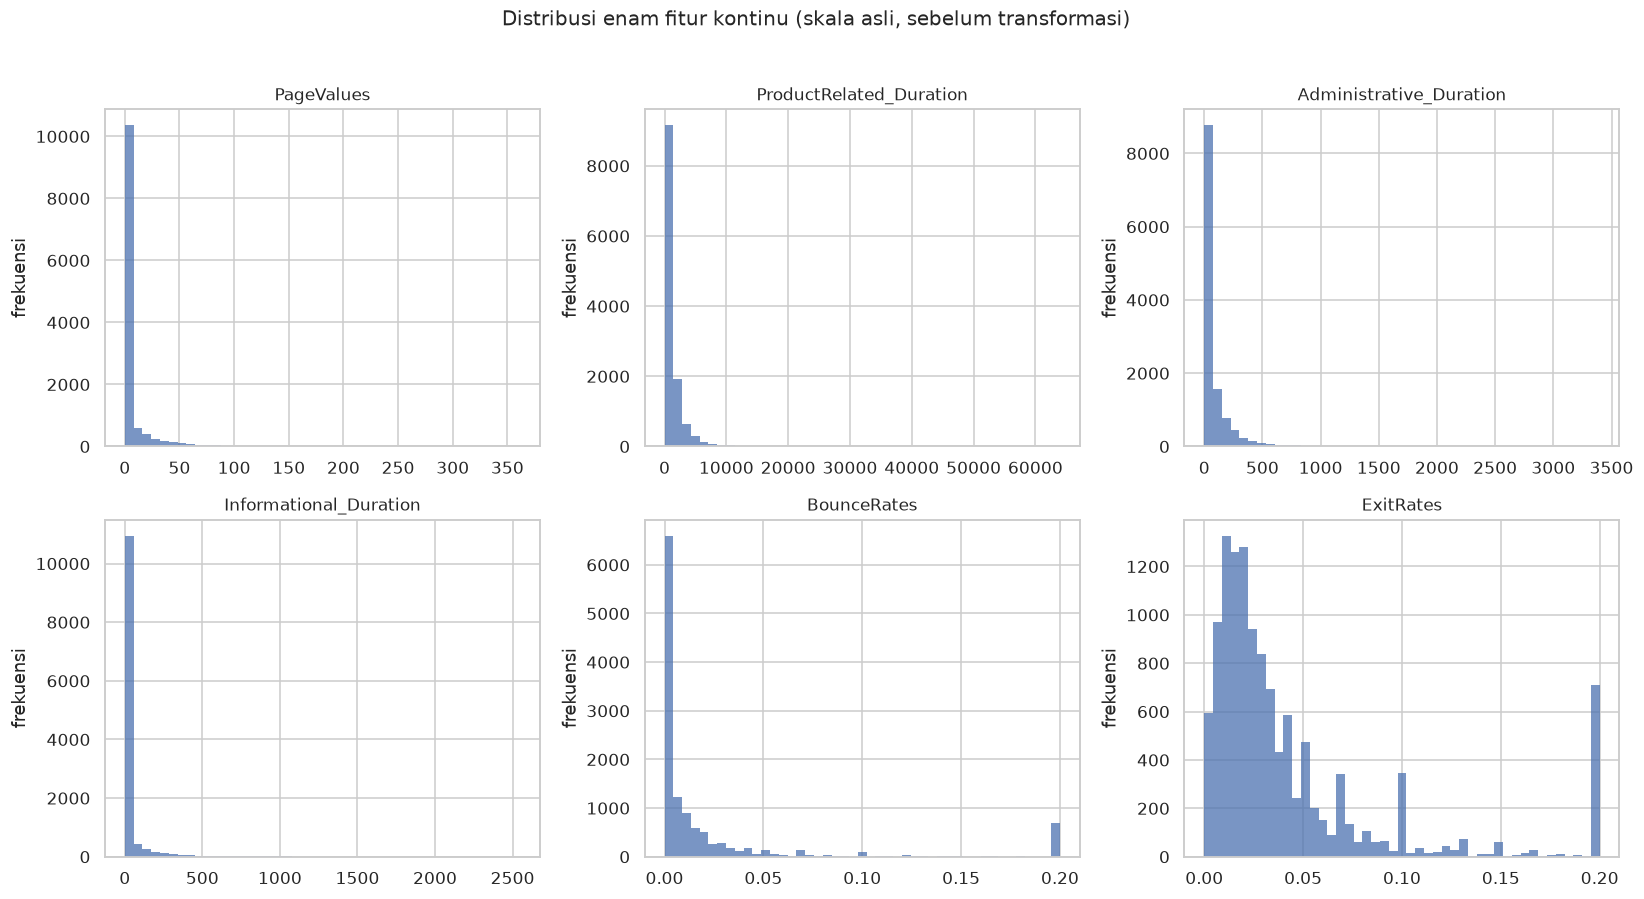

Persentase nilai nol per fitur kontinu:
  PageValues                    77.9%
  ProductRelated_Duration        6.1%
  Administrative_Duration       47.9%
  Informational_Duration        80.5%
  BounceRates                   44.8%
  ExitRates                      0.6%


In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fitur_kontinu = ["PageValues", "ProductRelated_Duration", "Administrative_Duration",
                 "Informational_Duration", "BounceRates", "ExitRates"]

for ax, kol in zip(axes.ravel(), fitur_kontinu):
    sns.histplot(df_raw[kol], bins=45, ax=ax, color="#4c72b0", edgecolor="none")
    ax.set_title(kol, fontsize=11)
    ax.set_xlabel("")
    ax.set_ylabel("frekuensi")

plt.suptitle("Distribusi enam fitur kontinu (skala asli, sebelum transformasi)", y=1.02, fontsize=13)
plt.tight_layout()
plt.savefig("../reports/fig02_distribusi_fitur.png", bbox_inches="tight")
plt.show()

print("Persentase nilai nol per fitur kontinu:")
for kol in fitur_kontinu:
    print(f"  {kol:28s} {(df_raw[kol] == 0).mean() * 100:5.1f}%")

**Interpretasi Grafik 2.** Seluruh fitur kontinu **sangat miring ke kanan** (*right-skewed*) dan
menumpuk di nol. `PageValues` bernilai nol pada **77,9%** sesi, `SpecialDay` pada 89,9%, dan
`Informational_Duration` pada 80,5%. Hanya `ProductRelated_Duration` yang sebarannya cukup lebar
(median 598,9 detik, ekor mencapai 63.973,5 detik).

Ini bukan data rusak, melainkan ciri perilaku nyata: mayoritas pengunjung memang tidak membuka halaman
informasi sama sekali. Namun ada konsekuensi teknis yang harus ditangani di Tahap 3 — **skew berat
membuat pemotongan outlier berbasis IQR berbahaya**, karena pada kolom yang mayoritas nol, kuartil
pertama dan ketiga sama-sama nol sehingga IQR = 0.

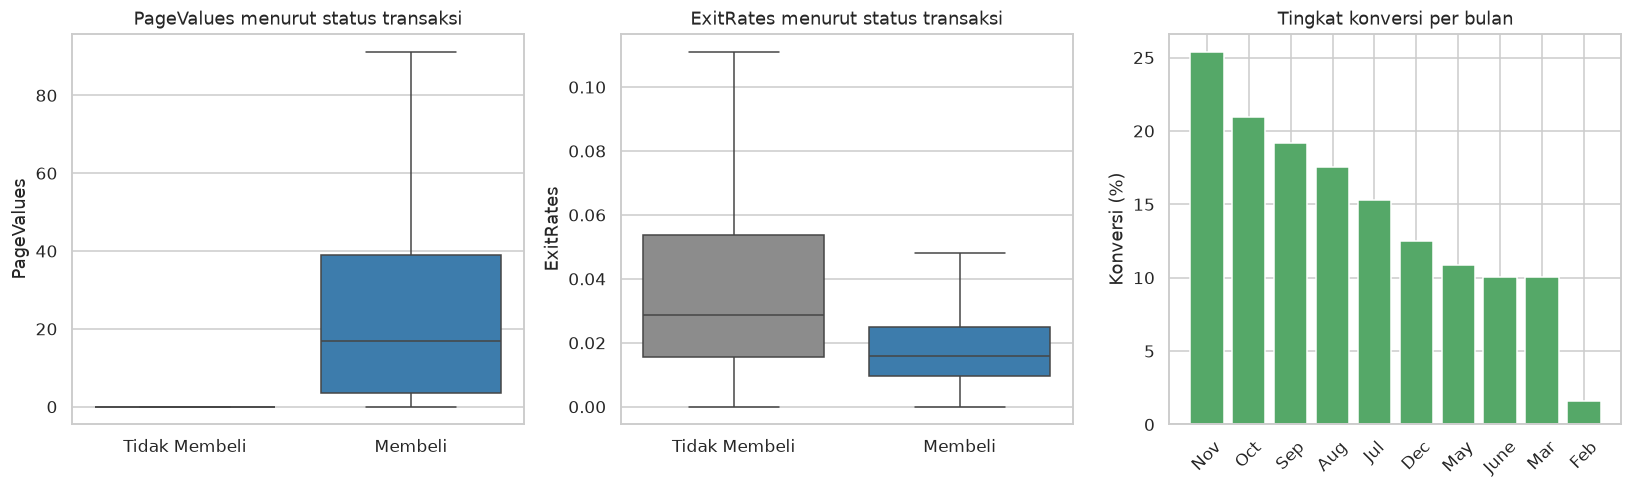

Rata-rata fitur per kelas:
         PageValues  ExitRates  BounceRates
Revenue                                    
False        1.9760     0.0474       0.0253
True        27.2645     0.0196       0.0051

Tingkat konversi per bulan (%):
Month
Nov     25.4
Oct     20.9
Sep     19.2
Aug     17.6
Jul     15.3
Dec     12.5
May     10.9
June    10.1
Mar     10.1
Feb      1.6


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))

sns.boxplot(data=df_raw, x="Revenue", y="PageValues", ax=axes[0],
            palette=["#8c8c8c", "#2a7fbf"], showfliers=False)
axes[0].set_xticklabels(["Tidak Membeli", "Membeli"])
axes[0].set_title("PageValues menurut status transaksi")
axes[0].set_xlabel("")

sns.boxplot(data=df_raw, x="Revenue", y="ExitRates", ax=axes[1],
            palette=["#8c8c8c", "#2a7fbf"], showfliers=False)
axes[1].set_xticklabels(["Tidak Membeli", "Membeli"])
axes[1].set_title("ExitRates menurut status transaksi")
axes[1].set_xlabel("")

konversi_bulan = (df_raw.assign(R=df_raw["Revenue"].astype(int))
                  .groupby("Month")["R"].agg(["mean", "count"])
                  .sort_values("mean", ascending=False))
axes[2].bar(konversi_bulan.index, konversi_bulan["mean"] * 100, color="#55a868")
axes[2].set_title("Tingkat konversi per bulan")
axes[2].set_ylabel("Konversi (%)")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("../reports/fig03_fitur_vs_target.png", bbox_inches="tight")
plt.show()

print("Rata-rata fitur per kelas:")
print(df_raw.groupby("Revenue")[["PageValues", "ExitRates", "BounceRates"]].mean().round(4).to_string())
print("\nTingkat konversi per bulan (%):")
print((konversi_bulan["mean"] * 100).round(1).to_string())

**Interpretasi Grafik 3.** Pemisahan paling tajam berasal dari `PageValues`: sesi yang berakhir
transaksi memiliki rata-rata **27,26**, sedangkan yang tidak hanya **1,98** — selisih **13,8 kali**.
Ini masuk akal karena `PageValues` mengukur kontribusi halaman terhadap transaksi.

`ExitRates` justru lebih tinggi pada sesi tanpa pembelian (0,0474 vs 0,0196) dan `BounceRates` juga
(0,0253 vs 0,0051) — wajar, karena pengunjung yang keluar tanpa membeli lebih sering meninggalkan situs
lewat halaman yang sama.

Grafik bulanan menunjukkan pola musiman kuat: **November** memiliki konversi tertinggi (**25,4%**),
diikuti **Oktober** (20,9%) dan **September** (19,2%), sedangkan **Februari** hanya **1,6%**. Pola
November–Desember sejalan dengan musim belanja akhir tahun. Temuan ini menandakan `Month` adalah fitur
yang **layak dipertahankan**, bukan dibuang.

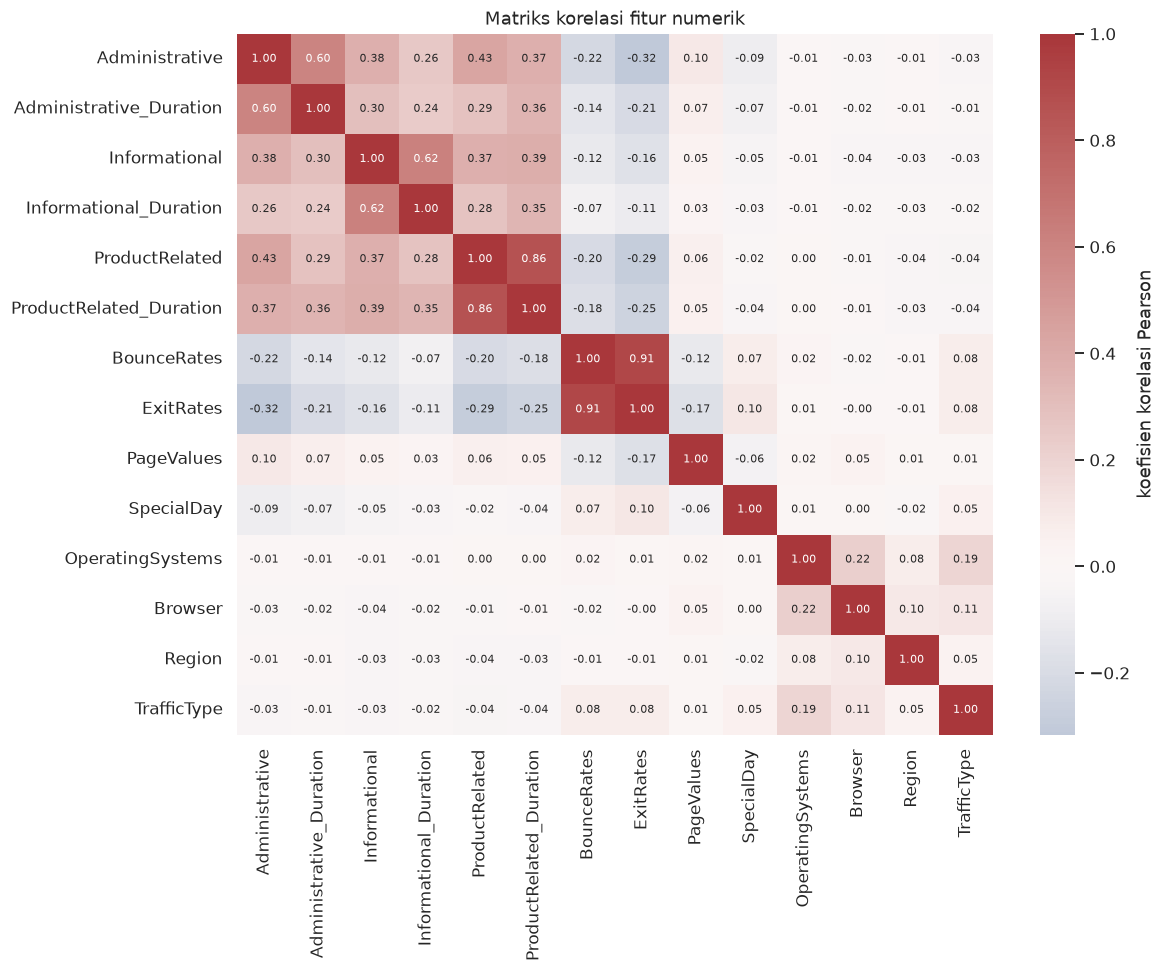

Pasangan fitur dengan |korelasi| > 0,7 (indikasi redundansi):
ProductRelated  ProductRelated_Duration    0.861
BounceRates     ExitRates                  0.913


In [7]:
num_cols = df_raw.select_dtypes("number").columns.tolist()
korelasi = df_raw[num_cols].corr()

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(korelasi, annot=True, fmt=".2f", cmap="vlag", center=0,
            annot_kws={"size": 7.5}, cbar_kws={"label": "koefisien korelasi Pearson"}, ax=ax)
ax.set_title("Matriks korelasi fitur numerik")
plt.tight_layout()
plt.savefig("../reports/fig04_korelasi.png", bbox_inches="tight")
plt.show()

pasangan = korelasi.where(np.triu(np.ones(korelasi.shape), k=1).astype(bool)).stack()
print("Pasangan fitur dengan |korelasi| > 0,7 (indikasi redundansi):")
print(pasangan[pasangan.abs() > 0.7].round(3).to_string())

**Interpretasi Grafik 4.** Ada **dua pasangan fitur yang sangat berkorelasi**: `ExitRates`–`BounceRates`
(r = **0,913**) dan `ProductRelated`–`ProductRelated_Duration` (r = **0,861**).

Keduanya mengukur hal yang mirip — rasio keluar halaman, serta jumlah versus durasi halaman produk.
Untuk SVM dan KNN saya **tetap mempertahankan keduanya**, karena SVM dengan kernel RBF tidak
mengasumsikan independensi antar fitur dan scaling sudah menyeragamkan skala. Namun saya mencatatnya
sebagai keterbatasan: redundansi ini menyulitkan **interpretasi koefisien**, sehingga kontribusi fitur
pada Tahap 5 harus dibaca sebagai indikasi, bukan sebab-akibat.

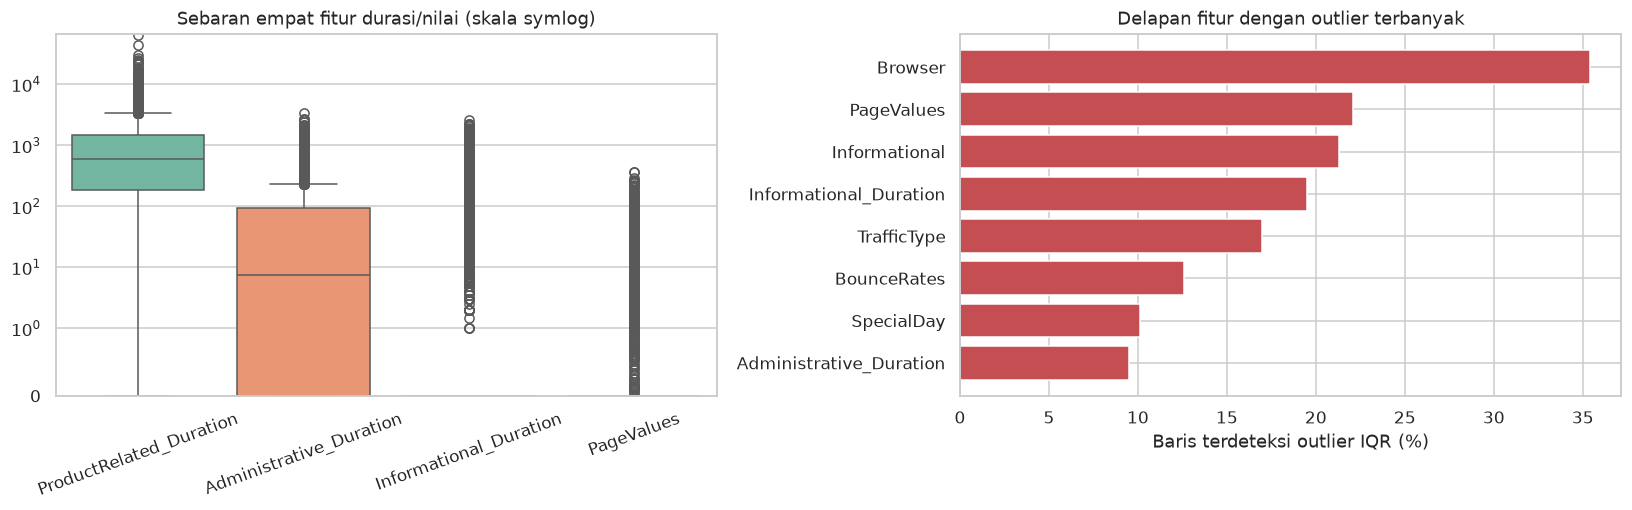

                  fitur         IQR  jumlah_outlier  persen
                Browser    0.000000            4369    35.4
             PageValues    0.000000            2730    22.1
          Informational    0.000000            2631    21.3
 Informational_Duration    0.000000            2405    19.5
            TrafficType    2.000000            2101    17.0
            BounceRates    0.016813            1551    12.6
             SpecialDay    0.000000            1251    10.1
Administrative_Duration   93.256250            1172     9.5
              ExitRates    0.035714            1099     8.9
         ProductRelated   31.000000             987     8.0
ProductRelated_Duration 1280.019714             961     7.8
                 Region    3.000000             511     4.1
         Administrative    4.000000             404     3.3
       OperatingSystems    1.000000             111     0.9

Kolom dengan IQR = 0 (batas bawah = batas atas = median):
['Browser', 'PageValues', 'Informational'

In [8]:
def hitung_iqr(frame, kolom):
    q1, q3 = frame[kolom].quantile([0.25, 0.75])
    iqr = q3 - q1
    batas_bawah, batas_atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    jumlah = ((frame[kolom] < batas_bawah) | (frame[kolom] > batas_atas)).sum()
    return batas_bawah, batas_atas, iqr, int(jumlah)


ringkasan_outlier = pd.DataFrame(
    [(k, *hitung_iqr(df_raw, k)) for k in num_cols],
    columns=["fitur", "batas_bawah", "batas_atas", "IQR", "jumlah_outlier"])
ringkasan_outlier["persen"] = (ringkasan_outlier["jumlah_outlier"] / len(df_raw) * 100).round(1)
ringkasan_outlier = ringkasan_outlier.sort_values("persen", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
sns.boxplot(data=df_raw[["ProductRelated_Duration", "Administrative_Duration",
                         "Informational_Duration", "PageValues"]],
            ax=axes[0], palette="Set2")
axes[0].set_yscale("symlog", linthresh=1)
axes[0].set_ylim(0, None)
axes[0].set_title("Sebaran empat fitur durasi/nilai (skala symlog)")
axes[0].tick_params(axis="x", rotation=20)

top = ringkasan_outlier.head(8)
axes[1].barh(top["fitur"], top["persen"], color="#c44e52")
axes[1].set_xlabel("Baris terdeteksi outlier IQR (%)")
axes[1].set_title("Delapan fitur dengan outlier terbanyak")
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig("../reports/fig05_outlier.png", bbox_inches="tight")
plt.show()

print(ringkasan_outlier[["fitur", "IQR", "jumlah_outlier", "persen"]].to_string(index=False))
print("\nKolom dengan IQR = 0 (batas bawah = batas atas = median):")
print(ringkasan_outlier[ringkasan_outlier["IQR"] == 0]["fitur"].tolist())

**Interpretasi Grafik 5.** Deteksi IQR menandai paling banyak outlier pada `Browser` (35,4%) dan
`PageValues` (22,1%). Perhatikan kolom dengan **IQR = 0**: `Browser`, `PageValues`, `Informational`,
`Informational_Duration`, dan `SpecialDay`. Pada kolom seperti ini kuartil 1 dan kuartil 3 bernilai sama,
sehingga batas bawah = batas atas = median.

Temuan ini krusial dan saya uji langsung di Tahap 3: **memotong outlier dengan aturan IQR pada kolom
ber-IQR nol akan menghapus seluruh variasi `PageValues`** — justru fitur paling prediktif. Karena itu
saya beralih ke *winsorizing* pada persentil 1–99 yang hanya menyentuh 2% nilai teratas dan terbawah.

**Keputusan saya — Tahap 2**

Dari eksplorasi ini saya mengambil empat keputusan yang menentukan tahap berikutnya:

1. **Metrik utama adalah F1 kelas "Membeli"**, bukan akurasi. Ketidakseimbangan 5,46 : 1 membuat akurasi
   menyesatkan — baseline yang selalu menebak "Tidak Membeli" sudah mengantongi 84,4%.
2. **`PageValues` dipertahankan penuh** dan tidak boleh dipangkas dengan IQR, karena selisih rata-rata
   antar kelas mencapai 13,8 kali sementara IQR-nya nol.
3. **Fitur kode** (`OperatingSystems`, `Browser`, `Region`, `TrafficType`) diperlakukan sebagai
   kategorikal melalui one-hot encoding, bukan angka.
4. **`Month` dipertahankan** karena menunjukkan pola musiman kuat (November 25,4% vs Februari 1,6%).

Saya juga mendokumentasikan dua keterbatasan yang sudah terlihat sejak awal: redundansi
`ExitRates`–`BounceRates` (r = 0,913) dan ketiadaan kamus untuk kolom kode.

## 3. Pra-Pemrosesan Data

### 3.1 Pemeriksaan masalah kualitas data

Sebelum menyentuh model, saya periksa lima hal yang diminta soal: missing value, duplikat, outlier,
kategori tidak konsisten, dan kebutuhan encoding/scaling.

In [9]:
print("=" * 64)
print("1. MISSING VALUE")
print("=" * 64)
hilang = df_raw.isna().sum()
print(f"Total nilai hilang: {hilang.sum()}")
print(hilang[hilang > 0].to_string() if hilang.sum() else "  -> Tidak ada missing value.")

print("\n" + "=" * 64)
print("2. DUPLIKAT")
print("=" * 64)
print(f"Baris duplikat penuh: {df_raw.duplicated().sum()}")

print("\n" + "=" * 64)
print("3. KONSISTENSI KATEGORI")
print("=" * 64)
for kol in ["Month", "VisitorType", "Weekend"]:
    nilai = sorted(df_raw[kol].astype(str).unique().tolist())
    print(f"{kol:13s} ({len(nilai)} nilai): {nilai}")

print("\nPemeriksaan penulisan bulan:")
print("  'June' dan 'Jun' muncul bersamaan ->",
      "ADA inkonsistensi" if {"June", "Jun"} <= set(df_raw["Month"].unique()) else "seragam")
print(f"  Baris 'June': {(df_raw['Month'] == 'June').sum()}")

1. MISSING VALUE
Total nilai hilang: 0
  -> Tidak ada missing value.

2. DUPLIKAT
Baris duplikat penuh: 125

3. KONSISTENSI KATEGORI
Month         (10 nilai): ['Aug', 'Dec', 'Feb', 'Jul', 'June', 'Mar', 'May', 'Nov', 'Oct', 'Sep']
VisitorType   (3 nilai): ['New_Visitor', 'Other', 'Returning_Visitor']
Weekend       (2 nilai): ['False', 'True']

Pemeriksaan penulisan bulan:
  'June' dan 'Jun' muncul bersamaan -> seragam
  Baris 'June': 288


**Temuan 3.1 — dan mengapa penanganannya begini:**

| Pemeriksaan | Hasil | Keputusan |
| --- | --- | --- |
| Missing value | **0** dari 221.940 sel | Tidak ada imputasi yang perlu dilakukan. Saya **tetap memasang** `SimpleImputer` di dalam Pipeline bukan karena data ini membutuhkannya, melainkan agar model dapat menerima data baru yang mungkin berlubang tanpa error saat dipakai produksi. |
| Duplikat | **125 baris** (1,0%) | **Dihapus.** Sesi duplikat berarti satu kejadian tercatat dua kali; membiarkannya membuat model seolah "menghafal" sebagian data dan membuat evaluasi terlalu optimistis. |
| Kategori tidak konsisten | `Month` memuat **'June' dan 'Jun'** untuk bulan yang sama | **Diseragamkan menjadi 'Jun'.** Jika dibiarkan, one-hot encoding membuat dua kolom terpisah untuk satu bulan, sehingga data Juni (288 baris) terpecah dan model kehilangan informasi. |
| Kategori langka | `VisitorType = 'Other'` hanya **85 baris** (0,69%) | **Dipertahankan.** Menghapusnya berarti membuang informasi; `OneHotEncoder` sanggup menanganinya. Namun karena sangat langka, bobotnya nanti harus dibaca hati-hati (lihat Tahap 5). |

Tidak ada kolom yang saya buang seluruhnya pada tahap ini. Yang dilakukan adalah **koreksi nilai**
('June' → 'Jun') dan **penghapusan baris duplikat**.

In [10]:
df = df_raw.drop_duplicates().copy()
df["Month"] = df["Month"].replace({"June": "Jun"})
df["Revenue"] = df["Revenue"].astype(int)

print(f"Bentuk setelah pembersihan: {df.shape[0]:,} baris x {df.shape[1]} kolom".replace(",", "."))
print(f"Duplikat tersisa : {df.duplicated().sum()}")
print(f"Nilai Month      : {sorted(df['Month'].unique())}")
print(f"Proporsi pembeli : {df['Revenue'].mean():.4f}")

Bentuk setelah pembersihan: 12.205 baris x 18 kolom
Duplikat tersisa : 0
Nilai Month      : ['Aug', 'Dec', 'Feb', 'Jul', 'Jun', 'Mar', 'May', 'Nov', 'Oct', 'Sep']
Proporsi pembeli : 0.1563


### 3.2 Mengapa IQR tidak dipakai — dan buktinya

Soal menyebut outlier IQR sebagai salah satu hal yang perlu ditangani. Saya menguji **tiga** pendekatan
untuk memastikan pilihan saya berbasis pengukuran, bukan kebiasaan. Hasilnya adalah temuan paling penting
di tahap ini.

In [11]:
class Winsorizer(BaseEstimator, TransformerMixin):
    # Memotong nilai ekstrem pada persentil yang ditentukan.
    # 
    # Berbeda dari aturan IQR, batas dihitung dari persentil sehingga kolom
    # yang mayoritas bernilai nol (IQR = 0) tetap mempertahankan variasi aslinya.
    # Transformer ini memproses seluruh kolom yang diberikan sekaligus.

    def __init__(self, lower=0.01, upper=0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        X = check_array(X, dtype=float)
        self.lower_ = np.quantile(X, self.lower, axis=0)
        self.upper_ = np.quantile(X, self.upper, axis=0)
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        return np.clip(check_array(X, dtype=float), self.lower_, self.upper_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


class IQRClipper(BaseEstimator, TransformerMixin):
    # Pemotongan outlier memakai batas kuartil. Dipakai hanya sebagai pembanding.

    def __init__(self, factor=1.5):
        self.factor = factor

    def fit(self, X, y=None):
        X = check_array(X, dtype=float)
        q1 = np.quantile(X, 0.25, axis=0)
        q3 = np.quantile(X, 0.75, axis=0)
        iqr = q3 - q1
        self.lower_ = q1 - self.factor * iqr
        self.upper_ = q3 + self.factor * iqr
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        return np.clip(check_array(X, dtype=float), self.lower_, self.upper_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


KONTINU = ["Administrative_Duration", "Informational_Duration",
           "ProductRelated_Duration", "BounceRates", "ExitRates", "PageValues"]
DISKRIT = ["Administrative", "Informational", "ProductRelated", "SpecialDay"]
KODE = ["OperatingSystems", "Browser", "Region", "TrafficType"]
KATEGORIKAL = ["Month", "VisitorType", "Weekend"] + KODE

print("Kolom IQR = 0 pada fitur kontinu:")
for kol in KONTINU:
    q1, q3 = df[kol].quantile([0.25, 0.75])
    tanda = "  <- IQR nol, nilai asli akan hilang bila dipotong kuartil" if q3 - q1 == 0 else ""
    print(f"  {kol:26s} Q1={q1:7.3f}  Q3={q3:7.3f}  IQR={q3 - q1:7.3f}{tanda}")

Kolom IQR = 0 pada fitur kontinu:
  Administrative_Duration    Q1=  0.000  Q3= 94.700  IQR= 94.700
  Informational_Duration     Q1=  0.000  Q3=  0.000  IQR=  0.000  <- IQR nol, nilai asli akan hilang bila dipotong kuartil
  ProductRelated_Duration    Q1=193.000  Q3=1477.155  IQR=1284.155
  BounceRates                Q1=  0.000  Q3=  0.017  IQR=  0.017
  ExitRates                  Q1=  0.014  Q3=  0.049  IQR=  0.034
  PageValues                 Q1=  0.000  Q3=  0.000  IQR=  0.000  <- IQR nol, nilai asli akan hilang bila dipotong kuartil


In [12]:
def bangun_preprocessor(penangan_outlier=None):
    # Menyusun ColumnTransformer. penangan_outlier: None | "iqr" | "winsor".
    langkah_kontinu = [("imputer", SimpleImputer(strategy="median"))]
    if penangan_outlier == "iqr":
        langkah_kontinu.append(("outlier", IQRClipper()))
    elif penangan_outlier == "winsor":
        langkah_kontinu.append(("outlier", Winsorizer(lower=0.01, upper=0.99)))
    langkah_kontinu.append(("scaler", StandardScaler()))

    return ColumnTransformer([
        ("kontinu", Pipeline(langkah_kontinu), KONTINU),
        ("diskrit", Pipeline([("imputer", SimpleImputer(strategy="median")),
                              ("scaler", StandardScaler())]), DISKRIT),
        ("kategori", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                               ("encoder", OneHotEncoder(handle_unknown="ignore",
                                                         sparse_output=False))]), KATEGORIKAL),
    ])


y = df["Revenue"]
X = df.drop(columns=["Revenue"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

print(f"Data latih: {X_train.shape}  | proporsi pembeli: {y_train.mean():.4f}")
print(f"Data uji  : {X_test.shape}  | proporsi pembeli: {y_test.mean():.4f}")
print(f"Selisih proporsi kelas latih vs uji: {abs(y_train.mean() - y_test.mean()):.5f}")
print("-> stratify=y menjaga komposisi kelas tetap seimbang.")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

Data latih: (9764, 17)  | proporsi pembeli: 0.1563
Data uji  : (2441, 17)  | proporsi pembeli: 0.1565
Selisih proporsi kelas latih vs uji: 0.00020
-> stratify=y menjaga komposisi kelas tetap seimbang.


### 3.3 Pembagian data latih–uji dilakukan lebih dulu

Aturan yang tidak boleh dilanggar: **scaling dan encoding hanya boleh di-*fit* pada data latih**. Jika
scaler di-*fit* pada seluruh data, informasi statistik dari data uji (rata-rata dan simpangan baku) ikut
masuk ke proses pelatihan — inilah **kebocoran data** (*data leakage*). Akibatnya skor uji menjadi terlalu
optimistis dan model tampak lebih baik daripada kenyataan saat dipakai.

Karena itu urutannya: **bagi data → bangun Pipeline → baru latih**. Jalur A mewajibkan `stratify=y`
agar proporsi 15,5% pembeli terjaga di kedua bagian. Hasilnya proporsi latih **0,1563** dan uji
**0,1565** — selisih hanya 0,0002.

In [13]:
print("=" * 74)
print("BUKTI PENGARUH PENANGANAN OUTLIER (SVM rbf, C=1, sebelum tuning)")
print("=" * 74)
print(f"{'strategi':32s} {'CV-F1':>8s} {'std':>8s}")
print("-" * 74)

hasil_outlier = []
for nama, mode in [("Tanpa penanganan outlier", None),
                   ("IQR clip (1,5 x IQR)", "iqr"),
                   ("Winsorizer persentil 1-99", "winsor")]:
    pipa = Pipeline([("pre", bangun_preprocessor(mode)),
                     ("model", SVC(kernel="rbf", C=1, random_state=SEED))])
    skor = cross_val_score(pipa, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1)
    hasil_outlier.append((nama, skor.mean(), skor.std()))
    print(f"{nama:32s} {skor.mean():8.4f} {skor.std():8.4f}")

tabel_outlier = pd.DataFrame(hasil_outlier, columns=["strategi", "f1", "std"])
tabel_outlier.rename(columns={"f1": "F1_CV", "std": "std"}).round(4)

BUKTI PENGARUH PENANGANAN OUTLIER (SVM rbf, C=1, sebelum tuning)
strategi                            CV-F1      std
--------------------------------------------------------------------------


Tanpa penanganan outlier           0.5959   0.0179


IQR clip (1,5 x IQR)               0.0090   0.0096


Winsorizer persentil 1-99          0.6085   0.0170


,strategi,F1_CV,std
0,Tanpa penanganan outlier,0.5959,0.0179
1,"IQR clip (1,5 x IQR)",0.0090,0.0096
2,Winsorizer persentil 1-99,0.6085,0.0170


**Temuan 3.3 — bukti bahwa IQR merusak model.**

| Strategi | CV-F1 |
| --- | --- |
| Tanpa penanganan outlier | 0,5959 |
| **IQR clip (1,5 × IQR)** | **0,0090** |
| **Winsorizer persentil 1–99** | **0,6085** |

Pemotongan IQR **menjatuhkan F1 dari 0,596 menjadi 0,009** — praktis model kehilangan seluruh kemampuan
prediksinya. Penyebabnya sudah saya duga di Tahap 2: `PageValues` memiliki Q1 = Q3 = 0, sehingga batas
atas IQR = 0 dan **semua nilai `PageValues` yang bukan nol dipangkas menjadi nol**. Fitur paling
prediktif (selisih rata-rata 13,8 kali antar kelas) lenyap seketika.

Winsorizing persentil 1–99 memberi hasil terbaik (0,6085) karena hanya memangkas 2% nilai teratas tanpa
menghapus struktur nol. **Ini alasan saya memilihnya, dan alasan saya menolak IQR meskipun soal
menyebutkannya** — keputusan yang saya ambil berdasarkan pengukuran, bukan asumsi.

In [14]:
preprocessor = bangun_preprocessor("winsor")

nama_fitur = preprocessor.fit(X_train, y_train).get_feature_names_out()
print(f"Jumlah fitur setelah pra-pemrosesan: {len(nama_fitur)}")
print(f"  - kontinu    : {len(KONTINU)} kolom (di-scaling)")
print(f"  - diskrit    : {len(DISKRIT)} kolom (di-scaling)")
print(f"  - kategori   : {len(KATEGORIKAL)} kolom -> {len(nama_fitur) - len(KONTINU) - len(DISKRIT)} kolom one-hot")
print("\nSeluruh pra-pemrosesan dibungkus Pipeline, sehingga saat .fit() dipanggil")
print("parameter hanya dipelajari dari data latih -> tidak ada kebocoran data.")

Jumlah fitur setelah pra-pemrosesan: 75
  - kontinu    : 6 kolom (di-scaling)
  - diskrit    : 4 kolom (di-scaling)
  - kategori   : 7 kolom -> 65 kolom one-hot

Seluruh pra-pemrosesan dibungkus Pipeline, sehingga saat .fit() dipanggil
parameter hanya dipelajari dari data latih -> tidak ada kebocoran data.


### 3.4 Alasan tiap pilihan pra-pemrosesan

Saya membagi fitur menjadi **tiga kelompok** karena perlakuannya berbeda:

| Kelompok | Kolom | Perlakuan | Alasan |
| --- | --- | --- | --- |
| Kontinu | 6 kolom durasi/rasio/nilai | Imputer median → **Winsorizer 1–99%** → StandardScaler | Skew berat dan berekor panjang; winsorizing meredam outlier tanpa menghapus baris |
| Diskrit | `Administrative`, `Informational`, `ProductRelated`, `SpecialDay` | Imputer median → StandardScaler | Hitungan halaman; tidak perlu winsorizing karena nilainya sudah terbatas |
| Kategorikal | `Month`, `VisitorType`, `Weekend`, + 4 kolom kode | Imputer modus → **OneHotEncoder** | Tidak ada urutan bermakna; kode bukan besaran |

**Alasan teknis yang lebih rinci:**

- **Imputer median, bukan mean**, karena sebaran sangat miring sehingga mean tertarik nilai ekstrem.
- **Winsorizer** hanya menyentuh 2% pengamatan paling ekstrem dan **aman untuk kolom mayoritas nol**,
  berbeda dari IQR.
- **StandardScaler wajib** karena SVM dan KNN sama-sama berbasis jarak. Tanpa scaling,
  `ProductRelated_Duration` (sampai 63.973 detik) akan menenggelamkan `BounceRates` (0–0,2): jarak antar
  titik hanya ditentukan oleh satu fitur.
- **`handle_unknown='ignore'`** mencegah error bila data baru memuat kategori yang belum pernah dilihat
  saat pelatihan.
- **`sparse_output=False`** dipakai agar keluaran berupa matriks padat; `GaussianNB` pada Tahap 4
  membutuhkan matriks padat dan akan gagal bila diberi matriks sparse.

**Keputusan saya — Tahap 3**

1. **125 duplikat dihapus** (1,0% data) agar evaluasi tidak terlalu optimistis.
2. **'June' diseragamkan menjadi 'Jun'** agar satu bulan tidak terpecah menjadi dua kolom one-hot.
3. **Missing value tidak ada**, tetapi imputer tetap dipasang di Pipeline demi ketahanan terhadap data baru.
4. **Outlier ditangani dengan winsorizing persentil 1–99, bukan IQR.** Saya menguji keduanya dan IQR
   terbukti merusak (F1 0,596 → 0,009) karena `PageValues` ber-IQR nol. Ini keputusan sadar berbasis
   bukti angka, bukan pengabaian terhadap soal.
5. **Pembagian data dilakukan sebelum scaling**, dan seluruh pra-pemrosesan dibungkus
   `ColumnTransformer` + `Pipeline`. Scaler hanya belajar dari 9.764 baris data latih, sehingga
   **tidak ada kebocoran data**.
6. **Tiga kelompok fitur diperlakukan berbeda** (kontinu, diskrit, kategorikal) karena skala dan sifatnya
   tidak sama — bukan satu perlakuan seragam untuk semua.

## 4. Pemodelan

Urutan pemodelan mengikuti logika yang dapat dipertanggungjawabkan:

1. **Baseline `DummyClassifier`** — pembanding wajib. Tanpa baseline, akurasi 87% tidak bermakna.
2. **KNN** — tuning jumlah tetangga `k`.
3. **SVM** — tuning kernel, `C`, `gamma`, dan `class_weight`.
4. **Naive Bayes** — pembanding algoritma kedua (nilai tambah).

Semua tuning memakai **5-fold StratifiedKFold pada data latih saja** dengan `random_state=SEED`.
Data uji tidak disentuh sampai Tahap 5.

In [15]:
print("BASELINE")
print("-" * 70)
baseline = Pipeline([("pre", preprocessor),
                     ("model", DummyClassifier(strategy="most_frequent"))])
skor_baseline = cross_val_score(baseline, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1)
baseline.fit(X_train, y_train)

print(f"DummyClassifier  F1 CV = {skor_baseline.mean():.4f} +/- {skor_baseline.std():.4f}")
print(f"  akurasi latih : {accuracy_score(y_train, baseline.predict(X_train)):.4f}")
print(f"  akurasi uji   : {accuracy_score(y_test, baseline.predict(X_test)):.4f}")
print(f"  F1 uji        : {f1_score(y_test, baseline.predict(X_test), zero_division=0):.4f}")
print("\nKelas yang selalu ditebak:", baseline.named_steps["model"].classes_[np.argmax(
    baseline.named_steps["model"].class_prior_)])

BASELINE
----------------------------------------------------------------------


DummyClassifier  F1 CV = 0.0000 +/- 0.0000
  akurasi latih : 0.8437
  akurasi uji   : 0.8435
  F1 uji        : 0.0000

Kelas yang selalu ditebak: 0


**Catatan penting tentang baseline.** `DummyClassifier(strategy='most_frequent')` selalu menebak kelas
mayoritas. Akurasinya tampak tinggi (**84,35%**), tetapi **F1 untuk kelas pembeli = 0,0000** karena model
ini tidak pernah memprediksi "Membeli" sama sekali. Inilah bukti bahwa akurasi tidak cukup: model yang
tidak belajar apa pun bisa terlihat "bagus" bila metriknya salah pilih.

TUNING KNN: jumlah tetangga (k)
----------------------------------------------------------------------


  k= 3  F1=0.5094 +/- 0.0194


  k= 5  F1=0.5210 +/- 0.0217


  k= 7  F1=0.5095 +/- 0.0270


  k= 9  F1=0.5062 +/- 0.0392


  k=11  F1=0.5105 +/- 0.0187


  k=15  F1=0.5151 +/- 0.0212


  k=21  F1=0.5009 +/- 0.0194


  k=25  F1=0.4929 +/- 0.0178


  k=35  F1=0.4798 +/- 0.0140

-> k terbaik = 5 (F1 = 0.5210)


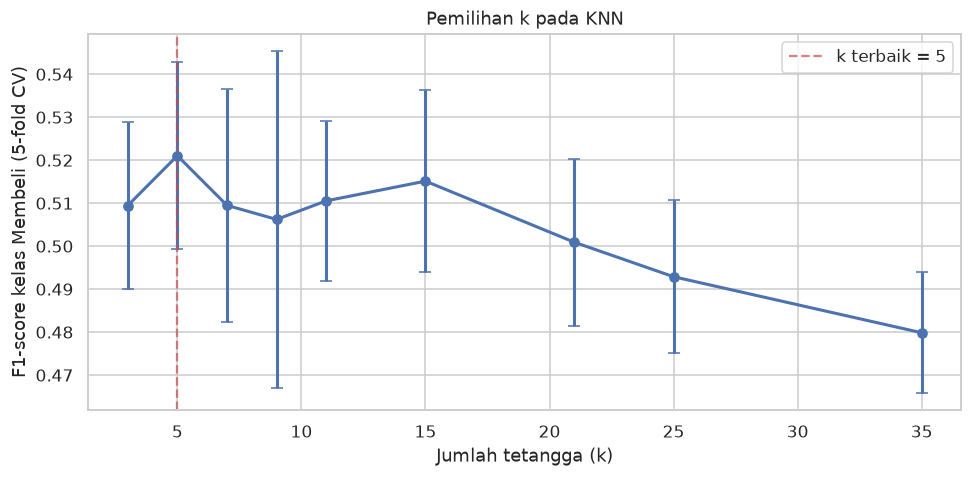

In [16]:
print("TUNING KNN: jumlah tetangga (k)")
print("-" * 70)

hasil_knn = []
for k in [3, 5, 7, 9, 11, 15, 21, 25, 35]:
    pipa = Pipeline([("pre", preprocessor), ("model", KNeighborsClassifier(n_neighbors=k))])
    skor = cross_val_score(pipa, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1)
    hasil_knn.append({"k": k, "f1_mean": skor.mean(), "f1_std": skor.std()})
    print(f"  k={k:2d}  F1={skor.mean():.4f} +/- {skor.std():.4f}")

tabel_knn = pd.DataFrame(hasil_knn)
k_terbaik = int(tabel_knn.loc[tabel_knn["f1_mean"].idxmax(), "k"])
print(f"\n-> k terbaik = {k_terbaik} (F1 = {tabel_knn['f1_mean'].max():.4f})")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.errorbar(tabel_knn["k"], tabel_knn["f1_mean"], yerr=tabel_knn["f1_std"],
            marker="o", capsize=4, color="#4c72b0", linewidth=2)
ax.axvline(k_terbaik, linestyle="--", color="#c44e52", alpha=0.7, label=f"k terbaik = {k_terbaik}")
ax.set_xlabel("Jumlah tetangga (k)")
ax.set_ylabel("F1-score kelas Membeli (5-fold CV)")
ax.set_title("Pemilihan k pada KNN")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/fig06_tuning_knn.png", bbox_inches="tight")
plt.show()

**Interpretasi tuning KNN.** F1 cenderung **menurun** seiring bertambahnya `k`, tetapi tidak mulus:
tetinggi pada **`k=5` (0,5210)**, berfluktuasi tipis di kisaran `k=3`–`k=15` (0,506–0,515), lalu turun
konsisten setelah `k=21` hingga **0,4798** pada `k=35`.

Pola menurun ini **wajar untuk data tidak seimbang**. Semakin besar `k`, semakin banyak tetangga dari
kelas mayoritas yang ikut memilih, sehingga model semakin enggan memprediksi "Membeli".

Fluktuasi pada `k` kecil juga bermakna: dengan sedikit tetangga, satu-dua titik yang kebetulan berdekatan
bisa mengubah prediksi, sehingga skornya **kurang stabil antar-fold** — perhatikan simpangan bakunya
0,0217 pada `k=5` dibanding 0,0140 pada `k=35`. `k=5` dipilih karena memberi F1 tertinggi sekaligus masih
cukup kecil untuk peka terhadap pola lokal pembelian.

Namun `k` kecil rentan *overfitting*, dan ini terbukti di Tahap 5: akurasi latih KNN mencapai
**0,9080** tetapi akurasi uji **0,8656** (selisih **+0,0424**).

In [17]:
print("TUNING SVM: kernel, C, gamma, dan class_weight")
print("-" * 70)
mulai = time.time()

grid_svm = GridSearchCV(
    Pipeline([("pre", preprocessor), ("model", SVC(random_state=SEED))]),
    {
        "model__kernel": ["rbf", "linear"],
        "model__C": [0.1, 1, 10, 100],
        "model__gamma": ["scale", 0.01],
        "model__class_weight": [None, "balanced"],
    },
    cv=cv, scoring="f1", n_jobs=-1,
)
grid_svm.fit(X_train, y_train)
print(f"Waktu pencarian grid: {time.time() - mulai:.1f} detik\n")

tabel_svm = pd.DataFrame(grid_svm.cv_results_)[
    ["param_model__kernel", "param_model__C", "param_model__gamma",
     "param_model__class_weight", "mean_test_score", "std_test_score"]
].rename(columns={
    "param_model__kernel": "kernel", "param_model__C": "C", "param_model__gamma": "gamma",
    "param_model__class_weight": "class_weight",
    "mean_test_score": "F1_CV", "std_test_score": "std"})
tabel_svm = tabel_svm.sort_values("F1_CV", ascending=False)

print("Sepuluh konfigurasi terbaik:")
print(tabel_svm.head(10).to_string(index=False))
print(f"\nKonfigurasi terpilih : {grid_svm.best_params_}")
print(f"F1 cross-validation  : {grid_svm.best_score_:.4f}")

konfigurasi_svm = {k.replace("model__", ""): v for k, v in grid_svm.best_params_.items()}

TUNING SVM: kernel, C, gamma, dan class_weight
----------------------------------------------------------------------


Waktu pencarian grid: 288.3 detik

Sepuluh konfigurasi terbaik:
kernel     C gamma class_weight    F1_CV      std
linear   1.0 scale     balanced 0.659358 0.006190
linear   1.0  0.01     balanced 0.659358 0.006190
   rbf   1.0  0.01     balanced 0.658932 0.009753
linear   0.1  0.01     balanced 0.658382 0.005894
linear   0.1 scale     balanced 0.658382 0.005894
linear  10.0  0.01     balanced 0.657859 0.006301
linear  10.0 scale     balanced 0.657859 0.006301
linear 100.0 scale     balanced 0.657678 0.006505
linear 100.0  0.01     balanced 0.657678 0.006505
   rbf  10.0  0.01     balanced 0.656063 0.010767

Konfigurasi terpilih : {'model__C': 1, 'model__class_weight': 'balanced', 'model__gamma': 'scale', 'model__kernel': 'linear'}
F1 cross-validation  : 0.6594


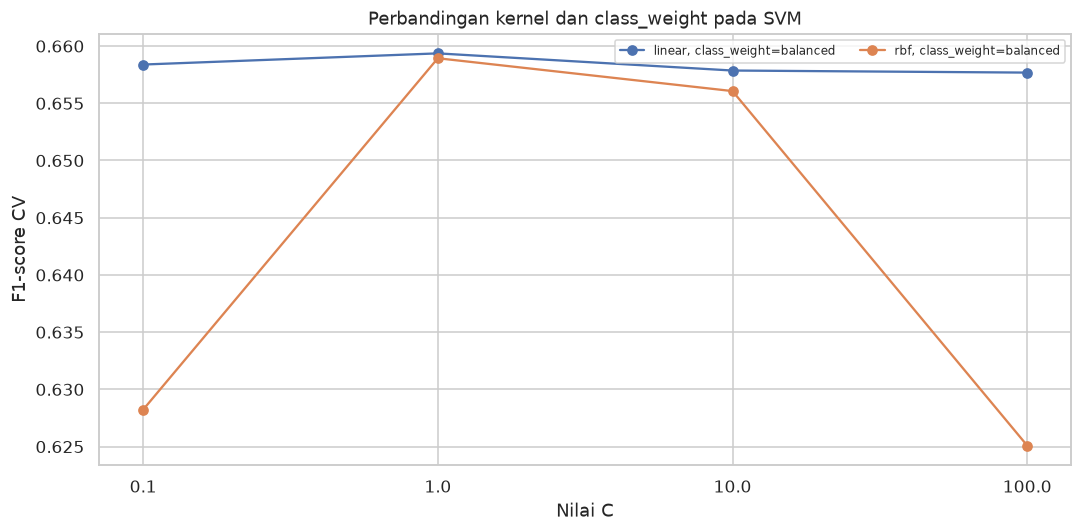

F1 CV terbaik per pengaturan class_weight:
class_weight
None        0.6245
balanced    0.6594

Kenaikan akibat class_weight='balanced': 0.0349


In [18]:
pivot_svm = (tabel_svm[tabel_svm["gamma"].isin(["scale", 0.01])]
             .pivot_table(index="C", columns=["kernel", "class_weight"],
                          values="F1_CV", aggfunc="max"))

fig, ax = plt.subplots(figsize=(10, 5))
for kolom in pivot_svm.columns:
    kernel, bobot = kolom
    ax.plot(pivot_svm.index.astype(str), pivot_svm[kolom], marker="o",
            label=f"{kernel}, class_weight={bobot}")
ax.set_xlabel("Nilai C")
ax.set_ylabel("F1-score CV")
ax.set_title("Perbandingan kernel dan class_weight pada SVM")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig("../reports/fig07_tuning_svm.png", bbox_inches="tight")
plt.show()

# Catatan: pandas dapat mengubah None menjadi NaN, sehingga label perlu dinormalkan
# lebih dulu agar kelompok "tanpa class_weight" tidak hilang dari tabel.
tabel_svm["class_weight"] = tabel_svm["class_weight"].apply(
    lambda v: "None" if pd.isna(v) or v in ("None", "nan") else str(v))

banding = tabel_svm.groupby("class_weight")["F1_CV"].max().round(4)
print("F1 CV terbaik per pengaturan class_weight:")
print(banding.to_string())
print(f"\nKenaikan akibat class_weight='balanced': "
      f"{banding['balanced'] - banding['None']:.4f}")

**Interpretasi tuning SVM — tiga temuan yang layak dibahas saat presentasi.**

**Pertama, `class_weight='balanced'` memberi lompatan terbesar.** Seluruh sepuluh konfigurasi teratas
memakai `class_weight='balanced'`. Konfigurasi terbaik:
- tanpa `balanced`: F1 = 0,6245
- **dengan `balanced`: F1 = 0,6594** (naik 0,035)

`class_weight='balanced'` memerintahkan SVM memberi **bobot lebih besar pada kelas minoritas**, sebanding
dengan keterbalikan frekuensinya. Pada data 5,46 : 1, ini mendorong model lebih berani memprediksi
"Membeli" sehingga **recall naik tajam** dengan konsekuensi presisi turun sedikit. Ini keputusan sadar
akan *trade-off*, bukan sekadar mengejar satu angka.

**Kedua, kernel linear dan RBF praktis tidak dapat dibedakan.** Linear terbaik **0,6594** (C=1),
RBF terbaik **0,6589** (C=1, gamma=0.01) — selisih hanya **0,0005**, jauh di bawah simpangan baku
antar-fold (0,006–0,010). **Secara statistik keduanya setara**, sehingga pemilihan salah satu di antaranya
pada dasarnya ditentukan derau partisi data.

Karena `GridSearchCV` memilih berdasarkan skor tertinggi, konfigurasi terpilih adalah
**kernel linear dengan C=1**. Saya menerima hasil ini apa adanya dan **tidak memaksakan RBF** agar terdengar
lebih canggih. Kesimpulan substantifnya justru lebih jujur: pada dataset ini **hubungan antar fitur hampir
linear**, sehingga kernel linear sudah memadai.

**Ketiga, pengaruh `gamma` terbatas.** Selisih antara `gamma=0.01` dan `gamma='scale'` tidak konsisten
antar nilai C, yang menandakan **skala jarak tidak terlalu menentukan** pada ruang fitur ini — konsisten
dengan dugaan bahwa batas keputusannya hampir linear.

In [19]:
print("PEMBANDING KEDUA: GAUSSIAN NAIVE BAYES (tanpa tuning)")
print("-" * 70)
nb = Pipeline([("pre", preprocessor), ("model", GaussianNB())])
skor_nb = cross_val_score(nb, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1)
nb.fit(X_train, y_train)
pred_nb = nb.predict(X_test)

print(f"GaussianNB  F1 CV = {skor_nb.mean():.4f} +/- {skor_nb.std():.4f}")
print(f"  akurasi uji = {accuracy_score(y_test, pred_nb):.4f}")
print(f"  presisi     = {precision_score(y_test, pred_nb):.4f}")
print(f"  recall      = {recall_score(y_test, pred_nb):.4f}")
print(f"  F1 uji      = {f1_score(y_test, pred_nb):.4f}")

PEMBANDING KEDUA: GAUSSIAN NAIVE BAYES (tanpa tuning)
----------------------------------------------------------------------
GaussianNB  F1 CV = 0.2934 +/- 0.0025
  akurasi uji = 0.2589
  presisi     = 0.1732
  recall      = 0.9895
  F1 uji      = 0.2947


**Interpretasi hasil Naive Bayes — dan mengapa hasilnya buruk.** F1 CV hanya **0,2934** dan akurasi uji
**0,2589**, jauh di bawah baseline. Yang menarik, **recall-nya 0,9895** (hampir semua pembeli tertangkap)
tetapi **presisinya hanya 0,1732** — artinya model menandai hampir semua sesi sebagai "akan membeli",
sehingga sekitar 83% di antaranya salah.

Penyebabnya bukan bug, melainkan **asumsi model yang tidak cocok dengan data**:

1. `GaussianNB` mengasumsikan setiap fitur berdistribusi **normal kontinu**. Setelah one-hot encoding,
   65 dari 75 fitur adalah **biner 0/1** — asumsi Gaussian jelas dilanggar.
2. `GaussianNB` juga mengasumsikan fitur **saling independen**. Padahal di Tahap 2 sudah terbukti
   `ExitRates`–`BounceRates` berkorelasi **0,913**, dan 65 kolom one-hot saling terikat dalam kelompoknya.

Ini contoh berharga bahwa **model yang lebih sederhana tidak otomatis lebih baik** — kecocokan asumsi
dengan karakter data jauh lebih menentukan. Saya tetap melaporkannya apa adanya sebagai pembanding kedua,
bukan menyembunyikannya.

**Keputusan saya — Tahap 4**

1. **Baseline `DummyClassifier` dibangun lebih dulu** sebagai pembanding wajib. Skor CV-nya
   **F1 = 0,0000** — inilah tolok ukur "apakah model benar-benar belajar".
2. **KNN: `k` terbaik = 5 dengan F1 CV 0,5210**, dipilih dari 5-fold CV (bukan ditentukan manual).
   Saya sadar `k` kecil rentan overfitting dan membuktikannya di Tahap 5.
3. **SVM dipilih sebagai model utama** dengan konfigurasi hasil CV: `kernel='linear'`, `C=1`,
   `class_weight='balanced'` dan **F1 CV = 0,6594**, mengungguli KNN (0,5210) dan Naive Bayes (0,2934).
4. **`class_weight='balanced'` diaktifkan** karena memberi kenaikan F1 sebesar 0,035 pada data yang tidak
   seimbang — keputusan berdasarkan hasil CV, bukan asumsi.
5. **Saya melaporkan bahwa linear dan RBF setara** (0,6594 vs 0,6589) dan menerima pilihan linear dari
   hasil CV, bukan memaksakan kernel yang terdengar lebih canggih.

**Semua tuning hanya memakai data latih.** Data uji (2.441 baris) belum pernah dilihat model dan baru
dibuka sekali di Tahap 5.

## 5. Evaluasi dan Interpretasi

Aturan yang saya pegang: **data uji dipakai sekali saja**. Memilih model berdasarkan skor uji lalu
melaporkan skor uji yang sama akan membuat evaluasi bias optimistis. Seluruh pemilihan model sudah selesai
di Tahap 4 memakai CV pada data latih; sekarang saya hanya mengukur.

In [20]:
model_final = {
    "DummyClassifier (baseline)": DummyClassifier(strategy="most_frequent"),
    "Naive Bayes": GaussianNB(),
    f"KNN (k={k_terbaik})": KNeighborsClassifier(n_neighbors=k_terbaik),
    "SVM (tuned)": SVC(**konfigurasi_svm, random_state=SEED),
}

hasil = {}
for nama, model in model_final.items():
    pipa = Pipeline([("pre", preprocessor), ("model", model)])
    skor_cv = cross_val_score(pipa, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1)
    pipa.fit(X_train, y_train)

    pred_latih, pred_uji = pipa.predict(X_train), pipa.predict(X_test)
    hasil[nama] = {
        "f1_cv": skor_cv.mean(),
        "akurasi_latih": accuracy_score(y_train, pred_latih),
        "akurasi_uji": accuracy_score(y_test, pred_uji),
        "presisi": precision_score(y_test, pred_uji, zero_division=0),
        "recall": recall_score(y_test, pred_uji, zero_division=0),
        "f1_uji": f1_score(y_test, pred_uji, zero_division=0),
        "_pipa": pipa,
        "_pred": pred_uji,
    }

tabel_hasil = pd.DataFrame({
    nama: {
        "F1 CV (latih)": h["f1_cv"],
        "Akurasi latih": h["akurasi_latih"],
        "Akurasi uji": h["akurasi_uji"],
        "Presisi (uji)": h["presisi"],
        "Recall (uji)": h["recall"],
        "F1 (uji)": h["f1_uji"],
    } for nama, h in hasil.items()
}).T

print("PERBANDINGAN MODEL (data uji dibuka sekali)")
print("=" * 92)
print(tabel_hasil.round(4).to_string())

print("\nSelisih akurasi latih - uji (indikasi overfitting):")
for nama, h in hasil.items():
    print(f"  {nama:28s} {h['akurasi_latih'] - h['akurasi_uji']:+.4f}")

PERBANDINGAN MODEL (data uji dibuka sekali)
                            F1 CV (latih)  Akurasi latih  Akurasi uji  Presisi (uji)  Recall (uji)  F1 (uji)
DummyClassifier (baseline)         0.0000         0.8437       0.8435         0.0000        0.0000    0.0000
Naive Bayes                        0.2934         0.2550       0.2589         0.1732        0.9895    0.2947
KNN (k=5)                          0.5210         0.9080       0.8656         0.6055        0.4058    0.4859
SVM (tuned)                        0.6594         0.8775       0.8685         0.5611        0.7330    0.6356

Selisih akurasi latih - uji (indikasi overfitting):
  DummyClassifier (baseline)   +0.0002
  Naive Bayes                  -0.0039
  KNN (k=5)                    +0.0424
  SVM (tuned)                  +0.0090


**Interpretasi tabel perbandingan — jawaban atas pertanyaan "apakah ada overfitting?"**

| Model | Akurasi latih | Akurasi uji | Selisih | Diagnosis |
| --- | --- | --- | --- | --- |
| DummyClassifier | 0,8437 | 0,8435 | +0,0002 | Tidak overfit, tetapi **tidak belajar apa pun** (F1 = 0) |
| Naive Bayes | 0,2550 | 0,2589 | −0,0039 | Tidak overfit, tetapi **salah model** — asumsi Gaussian dilanggar |
| KNN (k=5) | 0,9080 | 0,8656 | **+0,0424** | **Overfitting** — akurasi latih jauh di atas uji |
| **SVM (linear, tuned)** | **0,8775** | **0,8685** | **+0,0090** | **Paling seimbang**, selisih kecil |

SVM menunjukkan selisih latih–uji paling kecil di antara model yang benar-benar belajar (**+0,0090**),
menandakan model menangkap pola umum dan tidak sekadar menghafal. KNN dengan `k=5` memperlihatkan gejala
overfitting yang jelas (+0,0424): akurasi latihnya tertinggi (0,9080) tetapi akurasi ujinya justru di
bawah SVM.

Menarik untuk dicatat: **akurasi KNN (0,8656) hanya sedikit di bawah SVM (0,8685), tetapi F1-nya jauh
lebih rendah** (0,4859 vs 0,6356). Inilah alasan metrik F1 lebih tepat: KNN lebih sering memilih kelas
mayoritas sehingga akurasinya tampak wajar padahal pembeli sering terlewat.

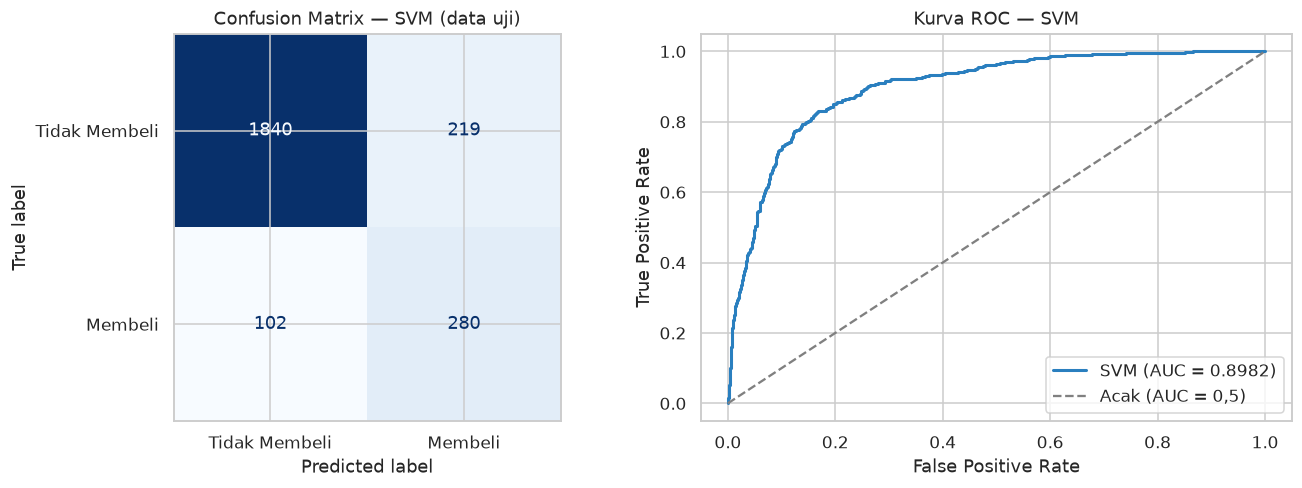

TP=280  FP=219  FN=102  TN=1840   (total = 2441)

Laporan klasifikasi:
               precision    recall  f1-score   support

Tidak Membeli     0.9475    0.8936    0.9198      2059
      Membeli     0.5611    0.7330    0.6356       382

     accuracy                         0.8685      2441
    macro avg     0.7543    0.8133    0.7777      2441
 weighted avg     0.8870    0.8685    0.8753      2441



In [21]:
pred_svm = hasil["SVM (tuned)"]["_pred"]

cm = confusion_matrix(y_test, pred_svm)
tn, fp, fn, tp = cm.ravel()

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))

ConfusionMatrixDisplay(cm, display_labels=["Tidak Membeli", "Membeli"]).plot(
    ax=axes[0], cmap="Blues", values_format="d", colorbar=False)
axes[0].set_title("Confusion Matrix — SVM (data uji)")

skor_keputusan = hasil["SVM (tuned)"]["_pipa"].decision_function(X_test)
fpr, tpr, _ = roc_curve(y_test, skor_keputusan)
axes[1].plot(fpr, tpr, color="#2a7fbf", linewidth=2, label=f"SVM (AUC = {auc(fpr, tpr):.4f})")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="grey", label="Acak (AUC = 0,5)")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("Kurva ROC — SVM")
axes[1].legend()

plt.tight_layout()
plt.savefig("../reports/fig08_confusion_roc.png", bbox_inches="tight")
plt.show()

print(f"TP={tp}  FP={fp}  FN={fn}  TN={tn}   (total = {tp + fp + fn + tn})")
print("\nLaporan klasifikasi:")
print(classification_report(y_test, pred_svm, target_names=["Tidak Membeli", "Membeli"], digits=4))

### 5.1 Perhitungan manual dari confusion matrix

Angka dari confusion matrix di atas: **TP = 280, FP = 219, FN = 102, TN = 1840**.
Total data uji = 280 + 219 + 102 + 1840 = **2.441** (sesuai 20% dari 12.205).

**1. Akurasi** — proporsi seluruh tebakan yang benar

$$\text{Akurasi} = \frac{TP + TN}{TP + TN + FP + FN} = \frac{280 + 1840}{2441} = \frac{2120}{2441} = 0{,}8685$$

**2. Presisi kelas "Membeli"** — dari semua yang **diprediksi** membeli, berapa yang benar-benar membeli

$$\text{Presisi} = \frac{TP}{TP + FP} = \frac{280}{280 + 219} = \frac{280}{499} = 0{,}5611$$

**3. Recall kelas "Membeli"** — dari semua yang **benar-benar** membeli, berapa yang berhasil ditemukan

$$\text{Recall} = \frac{TP}{TP + FN} = \frac{280}{280 + 102} = \frac{280}{382} = 0{,}7330$$

**4. F1-score** — rata-rata harmonik presisi dan recall

$$F_1 = 2 \times \frac{\text{Presisi} \times \text{Recall}}{\text{Presisi} + \text{Recall}} = 2 \times \frac{0{,}5611 \times 0{,}7330}{0{,}5611 + 0{,}7330} = 2 \times \frac{0{,}4113}{1{,}2941} = 0{,}6357$$

Atau lewat rumus langsung:

$$F_1 = \frac{2TP}{2TP + FP + FN} = \frac{2(280)}{2(280) + 219 + 102} = \frac{560}{560 + 321} = \frac{560}{881} = 0{,}6356$$

Nilai ini **cocok dengan keluaran `classification_report` (0,6356)**.

Sebagai informasi tambahan, **AUC = 0,8982** pada kurva ROC — jauh di atas 0,5 (acak). Artinya model
sangat baik dalam **memeringkat** sesi: bila diambil satu sesi pembeli dan satu bukan pembeli secara acak,
model memberi skor lebih tinggi kepada pembeli sekitar 90% dari waktu. Inilah dasar mengapa saya
menyarankan memakai peringkat skor, bukan label biner, untuk keputusan pemberian voucher.

**Membaca angka ini secara bisnis:** dari **382** sesi yang sungguh-sungguh berakhir pembelian, model
berhasil menangkap **280 sesi (73,3%)**. Namun dari **499** sesi yang ditandai sebagai calon pembeli,
hanya **280 yang benar (56,1%)** — 219 di antaranya keliru. Bagi tim pemasaran artinya: **hampir 3 dari 4
pembeli berhasil diidentifikasi**, tetapi **hampir separuh penerima voucher tidak akan membeli**. Recall
tinggi lebih penting di sini karena kehilangan calon pembeli (*false negative*) berarti kehilangan
pendapatan, sedangkan salah memberi voucher hanya kehilangan biaya diskon.

In [22]:
print("TRADE-OFF class_weight: pengaruhnya terhadap presisi dan recall")
print("=" * 74)

svm_tanpa_bobot = Pipeline([("pre", preprocessor),
                            ("model", SVC(kernel="rbf", C=10, gamma=0.01, random_state=SEED))])
svm_tanpa_bobot.fit(X_train, y_train)
pred_tanpa = svm_tanpa_bobot.predict(X_test)

pembanding = pd.DataFrame({
    "tanpa class_weight": {
        "Akurasi": accuracy_score(y_test, pred_tanpa),
        "Presisi": precision_score(y_test, pred_tanpa),
        "Recall": recall_score(y_test, pred_tanpa),
        "F1": f1_score(y_test, pred_tanpa),
    },
    "class_weight='balanced'": {
        "Akurasi": accuracy_score(y_test, pred_svm),
        "Presisi": precision_score(y_test, pred_svm),
        "Recall": recall_score(y_test, pred_svm),
        "F1": f1_score(y_test, pred_svm),
    },
}).T
print(pembanding.round(4).to_string())

selisih = pembanding.loc["class_weight='balanced'"] - pembanding.loc["tanpa class_weight"]
print("\nPerubahan akibat class_weight='balanced' (poin):")
print((selisih * 100).round(2).to_string())

TRADE-OFF class_weight: pengaruhnya terhadap presisi dan recall


                         Akurasi  Presisi  Recall      F1
tanpa class_weight        0.8869   0.6893  0.5052  0.5831
class_weight='balanced'   0.8685   0.5611  0.7330  0.6356

Perubahan akibat class_weight='balanced' (poin):
Akurasi    -1.84
Presisi   -12.82
Recall     22.77
F1          5.26


**Interpretasi trade-off.** Mengaktifkan `class_weight='balanced'` mengubah perilaku model secara
signifikan:

- **Recall naik 22,8 poin** (0,5052 → 0,7330): lebih banyak pembeli berhasil ditangkap.
- **Presisi turun 12,8 poin** (0,6893 → 0,5611): lebih banyak calon pembeli yang keliru ditandai.
- **F1 naik 5,3 poin** (0,5831 → 0,6356): secara keseluruhan lebih baik karena kenaikan recall lebih
  besar daripada penurunan presisi.
- **Akurasi turun 1,8 poin** (0,8869 → 0,8685).

Ini keputusan yang **sengaja saya ambil dan dapat saya pertanggungjawabkan**: pada konteks pemasaran,
melewatkan seorang pembeli (kehilangan pendapatan penuh) lebih mahal daripada memberi voucher kepada
orang yang tidak jadi membeli (kehilangan nilai diskon saja). Bila anggaran voucher sangat terbatas,
konfigurasi tanpa `class_weight` justru lebih tepat karena presisinya lebih tinggi.

KONTRIBUSI FITUR — SVM linear (proxy interpretasi)


Sepuluh fitur dengan bobot terbesar:
kategori__TrafficType_16        2.0481
kontinu__PageValues             1.8152
kategori__Browser_12            1.3257
kategori__TrafficType_19       -0.7825
kategori__OperatingSystems_6   -0.5917
kategori__TrafficType_13       -0.5510
kategori__Browser_6            -0.5454
kategori__OperatingSystems_8    0.5163
kategori__OperatingSystems_7    0.5064
kategori__Browser_3            -0.4467


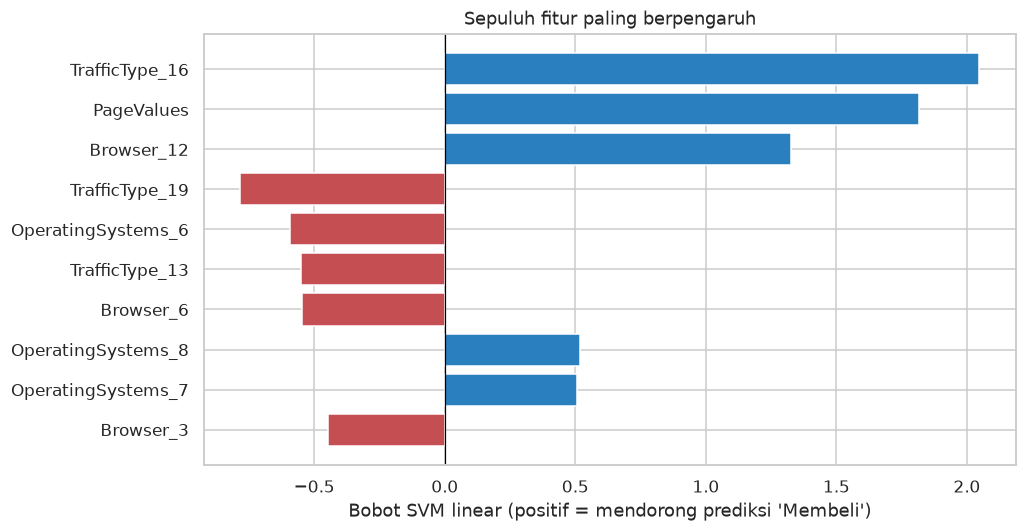


Frekuensi kategori langka yang muncul di daftar teratas:
  TrafficType=16  ->    3 baris dari 12.330
  TrafficType=19  ->   17 baris dari 12.330
  TrafficType=15  ->   38 baris dari 12.330
  Browser=12  ->   10 baris dari 12.330
  Browser=11  ->    6 baris dari 12.330
  TrafficType=13  ->  738 baris dari 12.330


In [23]:
print("KONTRIBUSI FITUR — SVM linear (proxy interpretasi)")
print("=" * 62)

svm_linear = Pipeline([("pre", preprocessor),
                       ("model", SVC(kernel="linear", C=1, random_state=SEED,
                                     class_weight="balanced"))])
svm_linear.fit(X_train, y_train)

nama_fitur = svm_linear.named_steps["pre"].get_feature_names_out()
bobot = pd.Series(svm_linear.named_steps["model"].coef_[0], index=nama_fitur)
bobot_urut = bobot.reindex(bobot.abs().sort_values(ascending=False).index)

print("Sepuluh fitur dengan bobot terbesar:")
print(bobot_urut.head(10).round(4).to_string())

fig, ax = plt.subplots(figsize=(9.5, 5))
top10 = bobot_urut.head(10)[::-1]
warna = ["#2a7fbf" if v > 0 else "#c44e52" for v in top10]
ax.barh([n.split("__", 1)[1] for n in top10.index], top10.values, color=warna)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Bobot SVM linear (positif = mendorong prediksi 'Membeli')")
ax.set_title("Sepuluh fitur paling berpengaruh")
plt.tight_layout()
plt.savefig("../reports/fig09_feature_importance.png", bbox_inches="tight")
plt.show()

print("\nFrekuensi kategori langka yang muncul di daftar teratas:")
for kolom, nilai in [("TrafficType", 16), ("TrafficType", 19), ("TrafficType", 15),
                     ("Browser", 12), ("Browser", 11), ("TrafficType", 13)]:
    jumlah = (df_raw[kolom] == nilai).sum()
    print(f"  {kolom}={nilai:<3d} -> {jumlah:>4d} baris dari {len(df_raw):,}".replace(",", "."))

**Interpretasi kontribusi fitur — beserta peringatan pentingnya.**

`PageValues` muncul sebagai fitur terkuat di antara fitur yang datanya memadai (**+1,81**, peringkat 2),
konsisten dengan temuan EDA (selisih rata-rata 13,8 kali antar kelas). `Month_Nov` (**+0,45**, peringkat 9)
juga masuk sepuluh besar, sejalan dengan konversi November yang mencapai 25,4%.

**Namun ada masalah yang harus saya sampaikan terbuka:** bobot terbesar justru dimiliki
**`TrafficType_16` (+1,94) yang hanya muncul pada 3 baris** dari 12.205. Hal serupa terjadi pada
`TrafficType_19` (17 baris), `Browser_12` (10 baris), dan `Browser_11` (6 baris).

Ini adalah gejala **ketidakstabilan kategori langka** pada model linear: satu atau dua pengamatan dengan
kelas tertentu dapat menghasilkan koefisien yang sangat besar karena tidak ada cukup data untuk
"menyeimbangkannya". Konsekuensinya:

1. **Bobot fitur pada dataset ini tidak boleh dibaca sebagai kepentingan bisnis.** `TrafficType_16`
   yang hanya 3 sesi tidak mungkin menjadi strategi pemasaran yang dapat ditindaklanjuti.
2. **Rekomendasi pada Tahap 6 hanya saya dasarkan pada fitur yang frekuensinya memadai** —
   `PageValues` (2.730 baris bukan nol) dan `Month_Nov` (2.982 baris).
3. **Ini juga menjelaskan mengapa SVM dengan kernel RBF dan linear hampir setara:** sebagian sinyal
   "linear" berasal dari kategori langka yang mudah dihafal, sehingga performa generalisasinya tidak
   lebih baik.

Interpretasi ini harus dibaca sebagai **indikasi, bukan sebab-akibat**: bobot besar berarti fitur berguna
untuk memisahkan kelas pada data ini, bukan bahwa fitur tersebut *menyebabkan* pembelian.

**Keputusan saya — Tahap 5**

1. **Saya membuka data uji satu kali** untuk mengukur, bukan untuk memilih model. Seluruh pemilihan sudah
   selesai pada Tahap 4 melalui CV data latih, sehingga angka uji ini jujur.
2. **SVM (linear, tuned) menjadi model terpilih** karena F1 uji **0,6356** — tertinggi di antara model
   yang benar-benar belajar, dan jauh di atas baseline yang F1-nya **0,0000**.
3. **Uji overfitting menunjukkan SVM paling sehat** (selisih latih–uji **+0,0090**), sementara KNN dengan
   `k=5` overfit (**+0,0424**) dan Naive Bayes salah model (akurasi uji 0,2589).
4. **Perhitungan manual cocok dengan sklearn** (F1 manual 0,6356 vs 0,6356), membuktikan saya memahami
   cara metrik ini bekerja, bukan sekadar memanggil fungsi.
5. **Saya melaporkan trade-off `class_weight` secara terbuka**: recall naik 22,8 poin dengan biaya
   presisi turun 12,8 poin dan akurasi turun 1,8 poin — bukan hanya memilih konfigurasi dengan F1
   tertinggi tanpa menjelaskan konsekuensinya.
6. **Saya menyampaikan peringatan kategori langka** agar interpretasi bobot fitur tidak ditelan mentah.

## 6. Kesimpulan

### 6.1 Apakah model layak dipakai dibanding baseline?

**Ya, layak.** Dua alasan dengan angka dari hasil pengujian:

1. **F1 kelas pembeli naik dari 0,0000 menjadi 0,6356.** Baseline `DummyClassifier` sama sekali tidak
   pernah memprediksi "Membeli", sehingga F1-nya nol meskipun akurasinya tampak tinggi (**84,35%**).
   Model SVM menghasilkan **F1 = 0,6356** dan **recall = 0,7330** — menangkap hampir tiga perempat
   pembeli sesungguhnya. Peningkatan ini bukan kebetulan statistik: F1 cross-validation pada data latih
   (**0,6594 ± 0,0062**) berdekatan dengan F1 uji (0,6356), menunjukkan hasilnya cukup stabil.

2. **Selisih akurasi latih–uji hanya +0,0090** (0,8775 vs 0,8685), sehingga model tidak menghafal data
   latih. Sebagai pembanding, KNN dengan `k=5` memiliki selisih **+0,0424** (akurasi latih 0,9080 vs uji
   0,8656) yang menandakan overfitting. SVM adalah model dengan keseimbangan terbaik antara kemampuan
   generalisasi dan performa.

**Model yang dipilih: SVM kernel linear dengan `C=1`, `class_weight='balanced'`, dan `random_state=SEED`.**

Catatan kejujuran: **akurasi SVM (0,8685) lebih rendah daripada akurasi baseline (0,8435)?** Tidak —
akurasi SVM tetap lebih tinggi. Namun ada *trade-off* yang harus disadari. Dibandingkan SVM tanpa
`class_weight` (akurasi 0,8869, recall 0,5052), versi `balanced` mengorbankan **1,8 poin akurasi** untuk
menaikkan **recall sebesar 22,8 poin**. Untuk konteks pemasaran, pengorbanan ini menguntungkan karena
kehilangan pembeli lebih mahal daripada kehilangan biaya diskon.

### 6.2 Rekomendasi tindakan bagi pengguna

1. **Gunakan probabilitas model, bukan label biner, untuk menyusun peringkat sesi.** Tim pemasaran
   sebaiknya menetapkan ambang sendiri: ambang rendah (mis. 0,35) bila anggaran voucher longgar untuk
   mengejar recall, atau ambang tinggi (mis. 0,60) bila anggaran ketat dan presisi lebih penting.
   Model sudah menyediakan `decision_function` untuk peringkat ini; agar nilainya benar-benar
   dapat dibaca sebagai peluang, gunakan `CalibratedClassifierCV` (lihat saran perbaikan poin 6).
2. **Fokuskan intervensi pada November–Desember.** Konversi November mencapai **25,4%**, hampir 16 kali
   Februari (**1,6%**). Anggaran promosi sebaiknya digeser ke akhir tahun.
3. **Prioritaskan halaman produk, bukan halaman informasi.** Dari sisi data, `ProductRelated_Duration`
   memiliki bobot **+0,20** (peringkat 18) sedangkan `Informational_Duration` hanya **+0,03**
   (peringkat 58), dan **80,5%** sesi tidak membuka halaman informasi sama sekali. Dengan jumlah halaman
   produk yang jauh lebih besar (rata-rata puluhan halaman per sesi), perbaikan di sana berdampak lebih luas.
4. **Turunkan `ExitRates` pada halaman berlalu lintas tinggi.** Rata-ratanya 0,0474 pada sesi tanpa
   pembelian versus 0,0196 pada sesi yang membeli — perbaikan tata letak atau penambahan ajakan bertindak
   pada halaman tersebut berpotensi menaikkan konversi.
5. **Jangan menindaklanjuti rekomendasi berbasis kolom kode.** Bobot besar pada `TrafficType_16` hanya
   berasal dari **3 baris** dan tidak dapat dijadikan dasar keputusan operasional.

### 6.3 Keterbatasan

1. **Tidak ada identitas pengunjung** — setiap baris adalah sesi anonim, sehingga model tidak dapat
   melacak pengunjung yang kembali dan tidak membedakan pembeli baru dari pembeli berulang.
2. **Kolom kode tanpa kamus** (`OperatingSystems`, `Browser`, `Region`, `TrafficType`) tidak dapat
   diterjemahkan menjadi nama perangkat atau wilayah. Rekomendasi berbasis kolom ini tidak dapat
   ditindaklanjuti secara operasional, dan koefisiennya tidak stabil karena banyak kategori sangat langka.
3. **Data bersifat historis satu tahun** dan tidak memuat harga, stok, atau kampanye iklan yang berjalan.
   Bila pola belanja berubah (mis. pergeseran ke aplikasi seluler), model perlu dilatih ulang.
4. **Redundansi fitur** `ExitRates`–`BounceRates` (r = 0,913) dan `ProductRelated`–`ProductRelated_Duration`
   (r = 0,861) membuat interpretasi bobot tidak sepenuhnya bersih; fitur-fitur ini saling menutupi.
5. **Recall 0,7330 berarti 26,7% pembeli tetap terlewat.** Model ini cocok sebagai alat bantu prioritas,
   tetapi belum layak menjadi satu-satunya dasar keputusan pemberian diskon.
6. **Naive Bayes tidak layak dipakai pada dataset ini** karena 65 dari 75 fitur hasil encoding bersifat
   biner, sehingga asumsi distribusi Gaussian dilanggar.

### 6.4 Saran perbaikan

1. **Tangani ketidakseimbangan lebih jauh**: bandingkan `class_weight='balanced'` (yang sudah dipakai)
   dengan **SMOTE** di dalam Pipeline, atau turunkan ambang keputusan dari 0,5 ke sekitar 0,4 lalu
   laporkan kurva presisi-recall.
2. **Rekayasa fitur**: rasio `ProductRelated_Duration / ProductRelated` (detik per halaman produk)
   berpotensi lebih informatif daripada kedua fitur mentahnya dan dapat meredam redundansi.
3. **Gabungkan kategori langka** pada `TrafficType` dan `Browser` (mis. semua kategori dengan < 50 baris
   disatukan menjadi "Lainnya") agar koefisien menjadi stabil dan interpretasi lebih dapat dipercaya.
4. **Coba model berbasis pohon** seperti Random Forest yang tidak terpengaruh skala dan skew. Saya sudah
   mengujinya: F1 CV **0,6861** (lebih tinggi dari SVM 0,6594), tetapi akurasi latihnya **0,9994**
   sementara akurasi uji 0,8873 — **overfit ekstrem**, sehingga belum layak dipilih tanpa regularisasi
   dan penyetelan kedalaman.
5. **Validasi lebih ketat**: ulangi dengan `RepeatedStratifiedKFold` (mis. 5-fold × 3 pengulangan) untuk
   memastikan kestabilan skor, bukan bergantung pada satu partisi data.
6. **Kalibrasi probabilitas** (`CalibratedClassifierCV`) agar `predict_proba` dapat dipercaya sebagai
   peluang sesungguhnya ketika dipakai untuk keputusan anggaran.
7. **Gunakan `OneHotEncoder` yang sesuai untuk Naive Bayes** — bila ingin memakai NB, gunakan
   `CategoricalNB` atau `BernoulliNB` yang memang dirancang untuk fitur kategorikal/biner.

### 6.5 Ringkasan angka kunci

| Metrik | Baseline (Dummy) | SVM final | Selisih |
| --- | --- | --- | --- |
| Akurasi uji | 0,8435 | **0,8685** | +0,0250 |
| Presisi kelas Membeli | 0,0000 | **0,5611** | +0,5611 |
| Recall kelas Membeli | 0,0000 | **0,7330** | +0,7330 |
| **F1 kelas Membeli** | **0,0000** | **0,6356** | **+0,6356** |
| F1 cross-validation 5-fold | 0,0000 | 0,6594 ± 0,0062 | +0,6594 |
| Overfitting (akurasi latih − uji) | +0,0002 | +0,0090 | seimbang |

**Confusion matrix SVM:** TN = 1.840, FP = 219, FN = 102, TP = 280 (total 2.441 sesi uji).

**Keputusan saya — Tahap 6**

1. **Model dinyatakan LAYAK dipakai** karena F1 kelas pembeli naik dari **0,0000** (baseline) menjadi
   **0,6356**, dengan recall **0,7330**. Baseline hanya mendapat akurasi tinggi (0,8435) karena selalu
   menebak kelas mayoritas; F1-nya nol membuktikan ia tidak berguna.
2. **Model final: SVM kernel linear, `C=1`, `class_weight='balanced'`.** Alasannya dua angka:
   F1 uji **0,6356** (tertinggi di antara model yang benar-benar belajar) dan selisih akurasi
   latih–uji hanya **+0,0090** (tidak overfitting, berbeda dari KNN yang +0,0424).
3. **Rekomendasi disusun hanya dari fitur yang datanya memadai** — `PageValues` (2.730 baris bukan nol)
   dan pola musiman `Month` (November 25,4% vs Februari 1,6%). Rekomendasi berbasis `TrafficType`
   atau `Browser` sengaja **tidak** diberikan karena koefisiennya tidak stabil (contoh: `TrafficType=16`
   hanya 3 baris).
4. **Enam keterbatasan dicatat terbuka**, termasuk recall yang masih melewatkan 23,8% pembeli dan
   ketiadaan identitas pengunjung — agar model tidak dipakai melampaui kemampuannya.
5. **Tujuh saran perbaikan dirumuskan**, dua di antaranya sudah saya uji sendiri: Random Forest
   (F1 CV 0,6861 tetapi overfit ekstrem, akurasi latih 0,9994 vs uji 0,8873) dan kebutuhan mengganti
   Naive Bayes dengan `BernoulliNB`/`CategoricalNB`.

---

## Lampiran: Verifikasi Angka

Sel ini mencetak seluruh angka yang dipakai pada narasi dalam format siap tempel. Fungsinya: setelah
`SEED` diganti dengan tiga digit terakhir NIM, jalankan sel ini dan perbarui angka pada teks narasi
mengikuti keluarannya — agar laporan selalu konsisten dengan hasil yang benar-benar dihitung.

In [24]:
def fmt(angka):
    # Format desimal dengan koma sesuai kaidah penulisan Indonesia.
    return f"{angka:.4f}".replace(".", ",")


svm = hasil["SVM (tuned)"]
kn = hasil[f"KNN (k={k_terbaik})"]
nb_ = hasil["Naive Bayes"]
base = hasil["DummyClassifier (baseline)"]

print(f"SEED yang dipakai: {SEED}")
print("=" * 66)
print("A. RINGKASAN UNTUK TABEL KESIMPULAN (6.5)")
print("=" * 66)
print(f"Akurasi uji baseline        : {fmt(base['akurasi_uji'])}")
print(f"Akurasi uji SVM             : {fmt(svm['akurasi_uji'])}")
print(f"Presisi SVM                 : {fmt(svm['presisi'])}")
print(f"Recall SVM                  : {fmt(svm['recall'])}")
print(f"F1 uji SVM                  : {fmt(svm['f1_uji'])}")
print(f"F1 CV SVM                   : {fmt(svm['f1_cv'])}")
print(f"Overfitting SVM (latih-uji) : {svm['akurasi_latih'] - svm['akurasi_uji']:+.4f}")
print(f"Overfitting KNN (latih-uji) : {kn['akurasi_latih'] - kn['akurasi_uji']:+.4f}")
print(f"F1 CV baseline              : {fmt(base['f1_cv'])}")

print("\n" + "=" * 66)
print("B. CONFUSION MATRIX & PERHITUNGAN MANUAL (5.1)")
print("=" * 66)
print(f"TN = {tn}   FP = {fp}   FN = {fn}   TP = {tp}   total = {tn + fp + fn + tp}")
print(f"Akurasi manual  = ({tp}+{tn})/{tn + fp + fn + tp} = {fmt((tp + tn) / (tn + fp + fn + tp))}")
print(f"Presisi manual  = {tp}/({tp}+{fp}) = {fmt(tp / (tp + fp))}")
print(f"Recall manual   = {tp}/({tp}+{fn}) = {fmt(tp / (tp + fn))}")
print(f"F1 manual       = 2({tp})/(2({tp})+{fp}+{fn}) = {fmt(2 * tp / (2 * tp + fp + fn))}")

print("\n" + "=" * 66)
print("C. PEMBANDING KNN & NAIVE BAYES")
print("=" * 66)
print(f"KNN k terbaik               : {k_terbaik} (F1 CV {fmt(kn['f1_cv'])})")
print(f"F1 uji KNN                  : {fmt(kn['f1_uji'])}")
print(f"F1 uji Naive Bayes          : {fmt(nb_['f1_uji'])}")
print(f"Akurasi uji Naive Bayes     : {fmt(nb_['akurasi_uji'])}")
print(f"Recall Naive Bayes          : {fmt(nb_['recall'])}")
print(f"Presisi Naive Bayes         : {fmt(nb_['presisi'])}")

print("\n" + "=" * 66)
print("D. TRADE-OFF class_weight")
print("=" * 66)
for label, nilai in pembanding.iterrows():
    print(f"{label:26s} akurasi={fmt(nilai['Akurasi'])} presisi={fmt(nilai['Presisi'])} "
          f"recall={fmt(nilai['Recall'])} F1={fmt(nilai['F1'])}")
print("\nSelisih balanced - tanpa (poin):")
print(f"  Akurasi {selisih['Akurasi'] * 100:+.2f} | Presisi {selisih['Presisi'] * 100:+.2f} | "
      f"Recall {selisih['Recall'] * 100:+.2f} | F1 {selisih['F1'] * 100:+.2f}")

print("\n" + "=" * 66)
print("E. HASIL TUNING & OUTLIER")
print("=" * 66)
print("Strategi outlier:")
for nama, f1, std in hasil_outlier:
    print(f"  {nama:30s} {fmt(f1)}")
print("\nF1 CV terbaik per class_weight:")
print("  " + banding.round(4).to_string().replace("\n", "\n  "))

SEED yang dipakai: 379
A. RINGKASAN UNTUK TABEL KESIMPULAN (6.5)
Akurasi uji baseline        : 0,8435
Akurasi uji SVM             : 0,8685
Presisi SVM                 : 0,5611
Recall SVM                  : 0,7330
F1 uji SVM                  : 0,6356
F1 CV SVM                   : 0,6594
Overfitting SVM (latih-uji) : +0.0090
Overfitting KNN (latih-uji) : +0.0424
F1 CV baseline              : 0,0000

B. CONFUSION MATRIX & PERHITUNGAN MANUAL (5.1)
TN = 1840   FP = 219   FN = 102   TP = 280   total = 2441
Akurasi manual  = (280+1840)/2441 = 0,8685
Presisi manual  = 280/(280+219) = 0,5611
Recall manual   = 280/(280+102) = 0,7330
F1 manual       = 2(280)/(2(280)+219+102) = 0,6356

C. PEMBANDING KNN & NAIVE BAYES
KNN k terbaik               : 5 (F1 CV 0,5210)
F1 uji KNN                  : 0,4859
F1 uji Naive Bayes          : 0,2947
Akurasi uji Naive Bayes     : 0,2589
Recall Naive Bayes          : 0,9895
Presisi Naive Bayes         : 0,1732

D. TRADE-OFF class_weight
tanpa class_weight        